# APAC codec results (standalone)

This notebook is a **self-contained** version of the repository hosted at (https://github.com/HexactlyA/idig4120_p2_codec) with a subsampled dataset and test-data: the complete codec implementation is included from the repository into the cell below. The prefered method of running would be to download the repository and run the `notebooks/codec_results.ipynb`.

Audio lives in `./fold1`, the folder next to this notebook. Every `*.wav` contained within is used. The demo sections reference four clips by name, so these must be present in `fold1`:

| clip | filename | why it is needed |
|---|---|---|
| street music | `124489-9-0-12.wav` | tonal demo, DCT players, LPC byte accounting |
| jackhammer | `98223-7-9-0.wav` | broadband demo, DCT head-to-head |
| engine idling | `176787-5-0-0.wav` | FLOAT subtype - the loader-bug section |
| street music 8k | `99180-9-0-0.wav` | identical channels - mid/side demo (synthetic fallback if absent) |

Size baseline throughout: the 16-bit PCM payload, `frames x channels x 2` bytes so compression ratios are payload-to-payload, not file-to-file.


In [42]:
# ==============================================================================================
# APAC audio codec - complete implementation, inlined verbatim from the repository.
#
# Normally this is a handful of imports (audio_codec.codec.codec, .format, .entropy,
# audio_codec.shared.load_file, audio_codec.config, evaluation) from the repository,
# which is the simpler way to run all of this. The requirements of the assignment call
# for a standalone notebook, so every module is pasted below, section by section:
#
#     config       - constants, wire enums, codec defaults
#     shared       - project logger + ValidationIssue
#     format       - APAC container: header + block framing
#     entropy      - Rice entropy coder
#     codec        - compress()/decompress() pipeline (the public API)
#     load_file    - WAV loading (subtype-routed to int16) + APAC file I/O
#     evaluation   - ratio/bitrate/SNR metrics
#
# The `from audio_codec... import ...` lines are dropped (every name is already defined
# in a section above); nothing else is changed. Third-party dependencies: numpy, soundfile.
# ==============================================================================================
from __future__ import annotations

# ==============================================================================
# inlined from src/audio_codec/config.py
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
'''
Central configuration, holds constants and defaults.

Also holds:
    - Wire-format enums and constants
    - Audio bounds
    - Prediction engine knobs
    - Whole-signal defaults
'''
import struct
from enum import IntEnum


class Predictor(IntEnum):
    NONE = 0
    FIXED = 1
    LPC = 2
    LMS = 3


class DCTMode(IntEnum):
    OFF = 0
    QUANTIZE = 1


class EntropyCoder(IntEnum):
    RICE = 0  #room for later coders NOTE: Currently no plans to add more coders


#--- wire format (format.py) ---
MAGIC = b"APAC"
VERSION = 1
HEADER_STRUCT = struct.Struct(">4sBHIQBBBBHBHIB")  #single source of truth for the 33-byte header layout NOTE: This is v1 and might be changed in other versions
MIN_SAMPLE_RATE = 1
MAX_SAMPLE_RATE = 2**32 - 1
MAX_BLOCK_SIZE_LOG2 = 20  #decoder allocation cap: 1 << this residuals per block (the byte field could hold 255 - DoS)
MIN_FRAMES = 0
MAX_FRAMES = 2**64 - 1
MIN_CHANNELS = 1
MAX_CHANNELS = 2**8 - 1
MIN_QUANT_STEP = 1
MAX_QUANT_STEP = 2**16 - 1
MIN_DCT_WINDOW_SIZE = 1
MAX_DCT_WINDOW_SIZE = 2**16 - 1
CONTROL_MODE_MASK = 0b00011111  #5 mode/k bits (0 = raw, 1-31 = Rice, k = mode - 1)
MODE_RAW = 0  #if k is 0 take raw PCM (avoids Rice coding cases where block size grows rather than shrink)
MODE_CONSTANT = 0b00100000  #control bit 5: constant block
MAX_RICE_K = 30  # k = mode - 1
LPC_PARAM_SIZE = 2  #bytes per LPC coefficient (int16); only used for LPC

#Valid predictor order per predictor (order must also fit its 1-byte header field)
PREDICTOR_ORDERS = {
    Predictor.NONE: range(0, 1),
    Predictor.FIXED: range(0, 5),
    Predictor.LPC: range(1, 256),
    Predictor.LMS: range(0, 256),
}

#--- int16 audio bounds (load_file.py quantization, codec.py clipping) ---
MIN_INT16 = -2**15
MAX_INT16 = 2**15 - 1

#--- prediction engine knobs (codec.py) ---
MAX_COEF = MAX_INT16  #LPC coefficient bounds (int16)
MIN_COEF = MIN_INT16
#Fixed polynomial predictor coefficients per order, max order 4. #TODO: consider expanding to higher orders
FIXED_COEFS = {0: [], 1: [1], 2: [2, -1], 3: [3, -3, 1], 4: [4, -6, 4, -1]}
LMS_MU = 0.1   #LMS adaptation strength, should be small to ensure stable convergence
LMS_EPS = 1.0  #normalizer floor, updates kept finite on quiet history
DCT_QUALITY_MIN = 1   #DCTMode.QUANTIZE quality bounds: 100 keeps every bin step at 1
DCT_QUALITY_MAX = 100
DCT_BASE_RAMP = 32   #QUANTIZE base table: bin step = window_size*k//32, tracks the windowed DCT-II gain

#--- whole-signal defaults(codec.py encode_pipeline) ---
DEFAULT_SETTINGS: dict = {
    "predictor": Predictor.FIXED,
    "predictor_order": 2,
    "block_size_log2": 10,
    "quant_step": 1,
    "dct_mode": DCTMode.OFF,
    "dct_window_size": 2**10, #1024
    "dct_param": 0,
    "entropy_coder": EntropyCoder.RICE,
}


# ==============================================================================
# inlined from src/audio_codec/shared/__init__.py + namespace shim (format.py logs via shared.logger)
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
import logging
import types

logger = logging.getLogger()  # shared logger for project to avoid one logger per module
shared = types.SimpleNamespace(logger=logger)  # the package keeps these under audio_codec.shared


# ==============================================================================
# inlined from src/audio_codec/shared/validation.py
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
#Contains the shared validation issue type used to collect all errors in one pass.

from dataclasses import dataclass


@dataclass(frozen=True)
class ValidationIssue:
    '''
    Holds information about a single validation failure.

    Attributes:
        - field (str): Name of the offending field.
        - message (str): Description of the validation failure.
    '''

    field: str
    message: str

    def __str__(self) -> str:
        return f"{self.field}: {self.message}"


# ==============================================================================
# inlined from src/audio_codec/codec/format.py
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
#Contains fileformat specifications and related utilities for the audio codec.

'''
    Format:

    Header | Data 

    #Note: Header optimization is more impactful in our case as most files are relatively short (not very impactful, but still worth considering)

    Header:
        | Magic bytes (4 bytes): "APAC" / 0x41504143 |
        | Version (1 byte) |
        | Header length (2 bytes) |
        | Sample rate (4 bytes) |
        | Sample count/frames (8 bytes) #TODO: consider 4 Byte (about 27 hours at 44.1 kHz) |
        | Channels (1 byte) #TODO: consider sub-byte as 255 channels will likely never be needed and try to align with another field for better packing |
        | Predictor (1 byte) #TODO: as only 3 predictors are planned at most this might be reduced to 2 bits and packed with other fields (6bit channeld + 2bit predictor?) |
        | Predictor Order (1 byte) |
        | Block size (1 byte) #TODO: represents 2**n samples (only 256 possible block sizes, might consider making smaller and packing as anything above 2**16 (65536) might be too many samples) |
        | Quantization step (for residuals) (2 bytes) |
        | DCT mode (1 byte) (off, quantize) |
        | DCT window size (2 bytes) #TODO: examine concequences of larger or smaller window sizes and reconsider |
        | DCT parameter (4 bytes) (spectral quality 1-100, 0 when off) |
        | Entropy coder (1 byte) (Rice coding) |
        #No reserved space as this is handled by version
        # Total header size = 4 + 1 + 2 + 4 + 8 + 1 + 1 + 1 + 1 + 2 + 1 + 2 + 4 + 1 = 33 bytes, Wav header = 44 bytes

    Data:
        Follows format:
        | Block 1 |
        | Block 2 |
        | ...     |

        Block:
            | Control (1 byte) | Predictor parameters (variable) | Block data |

        Control byte:
            | Reserved (2 bits) | Constant (1 bit) | Encoding mode / Rice k (5 bits) |
            -> |xx|c|xxxxx|
            
            Rice k / mode: 0 = raw PCM (int16)
            1-31 = Rice-coded residuals (k = value - 1)
            32 = constant block (bit 5 set), storing single int16 value to represent a constant block.

        Predictor parameters:
            
            Raw PCM: None
            Fixed: None (order stored in global header)
            LPC: Quantized coefficients (per block) (depends on predictor order)
            LMS: None (deterministic initialization/adaptation)

        Block data:
            Raw PCM:
                | Uncompressed int16 samples |

            Rice:
                | Rice-encoded quantized residuals | Byte padding |

'''


from dataclasses import dataclass, replace



#Wire-format constants, enums and limits live in audio_codec.config (single project config);
#imported here so every existing `from audio_codec.codec.format import ...` keeps resolving.


@dataclass(frozen=True)
class APACHeader:
    '''
        APAC audio codec header representation.

        Byte layout:
            |Offset|Size|Field|struct|
            |------|----|-----|------|
            | 0    | 4  | Magic `"APAC"`    | `4s`|
            | 4    | 1  | Version           | `B` |
            | 5    | 2  | Header length     | `H` |
            | 7    | 4  | Sample rate       | `I` |
            | 11   | 8  | Frames            | `Q` |
            | 19   | 1  | Channels          | `B` |
            | 20   | 1  | Predictor         | `B` |
            | 21   | 1  | Predictor order   | `B` |
            | 22   | 1  | Block size (2^n)  | `B` |
            | 23   | 2  | Quantization step | `H` |
            | 25   | 1  | DCT mode          | `B` |
            | 26   | 2  | DCT window size   | `H` |
            | 28   | 4  | DCT parameter     | `I` |
            | 32   | 1  | Entropy coder     | `B` |

    '''
    sample_rate: int
    frames: int
    channels: int
    predictor: Predictor
    predictor_order: int
    block_size_log2: int
    quant_step: int
    dct_mode: DCTMode
    dct_window_size: int
    dct_param: int
    entropy_coder: EntropyCoder


class FormatError(ValueError):
    '''Base class for APAC format errors.'''


class HeaderError(FormatError):
    '''
        Raised when a header is invalid.
        Can hold multiple validation issues.
    '''

    def __init__(self, issues: list[ValidationIssue]) -> None:
        self.issues = list(issues)
        summary = "; ".join(str(issue) for issue in self.issues)
        super().__init__(f"{len(self.issues)} invalid header field(s): {summary}")


class BlockError(FormatError):
    '''
        Raised when a block is malformed (bad mode, reserved bits set, truncation, bad params size).
    '''


def header_issues(header: APACHeader) -> list[ValidationIssue]:
    '''
        Validate APACHeader and return list of issues.

        Parameters:
            - header (APACHeader): The header to validate.

        Returns:
            - list[ValidationIssue]: List of issues found, empty if valid.
    '''
    checks: list[tuple[bool, str, str]] = [
        (
            MIN_SAMPLE_RATE <= header.sample_rate <= MAX_SAMPLE_RATE, 
            "sample_rate", 
            f"must be in the range [{MIN_SAMPLE_RATE}-{MAX_SAMPLE_RATE}], "
            f"got {header.sample_rate}"
        ),
        (
            MIN_FRAMES <= header.frames <= MAX_FRAMES,
            "frames",
            f"must be in the range [{MIN_FRAMES}-{MAX_FRAMES}], got {header.frames}"
        ),
        (
            MIN_CHANNELS <= header.channels <= MAX_CHANNELS,
            "channels",
            f"must be in the range [{MIN_CHANNELS}-{MAX_CHANNELS}], got {header.channels}"
        ),
        (
            0 < header.block_size_log2 <= MAX_BLOCK_SIZE_LOG2,
            "block_size_log2",
            f"must be in the range [1-{MAX_BLOCK_SIZE_LOG2}], got {header.block_size_log2}"
        ),
        (
            MIN_QUANT_STEP <= header.quant_step <= MAX_QUANT_STEP,
            "quant_step",
            f"must be in the range [{MIN_QUANT_STEP}-{MAX_QUANT_STEP}], got {header.quant_step}"
        ),
        (
            MIN_DCT_WINDOW_SIZE <= header.dct_window_size <= MAX_DCT_WINDOW_SIZE,
            "dct_window_size",
            f"must be in the range [{MIN_DCT_WINDOW_SIZE}-{MAX_DCT_WINDOW_SIZE}], got {header.dct_window_size}"
        ),
        (
            header.dct_param == 0 if header.dct_mode == DCTMode.OFF
            else DCT_QUALITY_MIN <= header.dct_param <= DCT_QUALITY_MAX,
            "dct_param",
            f"must be 0 for OFF or a spectral quality in [{DCT_QUALITY_MIN}-{DCT_QUALITY_MAX}] for QUANTIZE, got {header.dct_param}"
        ),
    ]
    issues = [ValidationIssue(field, message) for ok, field, message in checks if not ok]

    #Check enums
    if header.predictor not in Predictor.__members__.values():
        issues.append(ValidationIssue("predictor", f"unknown predictor value: {header.predictor}"))
    if header.dct_mode not in DCTMode.__members__.values():
        issues.append(ValidationIssue("dct_mode", f"unknown DCT mode value: {header.dct_mode}"))
    if header.entropy_coder not in EntropyCoder.__members__.values():
        issues.append(ValidationIssue("entropy_coder", f"unknown entropy coder value: {header.entropy_coder}"))

    #Valid order for given predictor
    if header.predictor in PREDICTOR_ORDERS:
        valid_orders = PREDICTOR_ORDERS[header.predictor]
        if header.predictor_order not in valid_orders:
            issues.append(ValidationIssue("predictor_order", f"must be in {valid_orders.start}..{valid_orders.stop - 1} for predictor {Predictor(header.predictor).name}, got {header.predictor_order}"))

    return issues


def validate_header(header: APACHeader) -> None:
    '''
    Validate an APACHeader, raises HeaderError.

    Parameters:
        - header (APACHeader): The header to validate.
    '''
    issues = header_issues(header)
    if issues:
        raise HeaderError(issues)


def encode_header(header: APACHeader) -> bytes:
    '''
        Pack an APACHeader into bytes.

        Parameters:
            - header (APACHeader): The header to encode.

        Returns:
            - bytes: The encoded header bytes.

        Raises:
            - HeaderError: If the header is invalid.
    '''
    
    validate_header(header)

    return HEADER_STRUCT.pack(
        MAGIC, VERSION, HEADER_STRUCT.size,
        header.sample_rate, header.frames, header.channels,
        header.predictor, header.predictor_order, header.block_size_log2,
        header.quant_step, header.dct_mode, header.dct_window_size,
        header.dct_param, header.entropy_coder,
    )


def decode_header(data: bytes) -> APACHeader:
    '''
        Unpack an APACHeader from the start of data.

        Parameters:
            - data (bytes): The byte sequence containing the header at the start.

        Returns:
            - APACHeader: The decoded header object.
            
        Raises:
            - FormatError: If the data is truncated or has bad magic/version/length.
            - HeaderError: If the decoded header is invalid.
    '''
    shared.logger.debug("Decoding APAC header from data of length %d", len(data))

    if len(data) < HEADER_STRUCT.size:
        raise FormatError(f"truncated header: expected {HEADER_STRUCT.size} bytes, got {len(data)}")
    
    magic, version, header_len, sample_rate, frames, channels, predictor, predictor_order, block_size_log2, quant_step, dct_mode, dct_window_size, dct_param, entropy_coder = HEADER_STRUCT.unpack_from(data)

    shared.logger.debug(
        f"Unpacked header fields: magic={magic!r}, version={version!r}, "
        f"header_len={header_len}, sample_rate={sample_rate}, frames={frames}, "
        f"channels={channels}, predictor={predictor}, predictor_order={predictor_order}, "
        f"block_size_log2={block_size_log2}, quant_step={quant_step}, dct_mode={dct_mode}, "
        f"dct_window_size={dct_window_size}, dct_param={dct_param}, entropy_coder={entropy_coder}"
    )
    
    if magic != MAGIC:
        raise FormatError(f"not an APAC file: bad magic bytes {magic!r}")
    
    if version != VERSION:
        raise FormatError(f"unsupported version {version}, expected {VERSION}")
    
    if header_len != HEADER_STRUCT.size:
        raise FormatError(f"bad header length {header_len}, expected {HEADER_STRUCT.size}")
    
    header = APACHeader(
        sample_rate=sample_rate, frames=frames, channels=channels,
        predictor=predictor, predictor_order=predictor_order, block_size_log2=block_size_log2,
        quant_step=quant_step, dct_mode=dct_mode, dct_window_size=dct_window_size,
        dct_param=dct_param, entropy_coder=entropy_coder
    )

    issues = header_issues(header)

    if issues:
        raise HeaderError(issues)

    shared.logger.debug("Header validation passed")
    
    #Ints to enums
    return replace(header, predictor=Predictor(predictor), dct_mode=DCTMode(dct_mode), entropy_coder=EntropyCoder(entropy_coder))


def predictor_params_size(header: APACHeader) -> int:
    '''
        Returns bytesize of predictor coefficients for LPC, else 0.

        Parameters:
            - header (APACHeader): The header describing the blocks.

        Returns:
            - int: LPC_PARAM_SIZE * predictor_order for LPC, 0 for every other predictor.
    '''
    if header.predictor == Predictor.LPC:
        return LPC_PARAM_SIZE * header.predictor_order
    return 0


def encode_control(mode: int) -> int:
    '''
        Builds control block with 2 reserved bits, 1 constant block bit and 5 used for Rice parameter k (0-30 (mode-1)) (raw PCM if mode is 0, constant block if mode is MODE_CONSTANT).

        Parameters:
            - mode: Value to encode into the control byte.
        
        Returns:
            - The encoded control byte as an integer.

        Raises:
            - BlockError: If mode not in [0-31] and not MODE_CONSTANT.
    '''
    if mode != MODE_CONSTANT and not 0 <= mode <= CONTROL_MODE_MASK:
        raise BlockError(f"invalid control mode, got {mode} expected [0-{CONTROL_MODE_MASK}] or {MODE_CONSTANT}")
    
    return mode


def decode_control(control: int) -> int:
    '''
        Decodes control byte to extract the mode/k value.
    
        Parameters:
            - control: The control byte to decode.

        Returns:
            - The extracted mode/k value as an integer.

        Raises:
            - BlockError: If reserved bits are set in the control byte or the constant bit is mixed with mode bits.
    '''
    if control & ~(CONTROL_MODE_MASK | MODE_CONSTANT):
        raise BlockError(f"invalid control byte, reserved bits set: {control:08b}")

    if control & MODE_CONSTANT and control & CONTROL_MODE_MASK:
        raise BlockError(f"invalid control byte, constant bit mixed with mode bits: {control:08b}")
    
    return control


def encode_block(mode: int, predictor_params: bytes, block_data: bytes) -> bytes:
    '''
        Frame one block as control byte + predictor parameters + block data.

        Parameters:
            - mode: The mode/k value for the block.
            - predictor_params: The predictor parameters as bytes.
            - block_data: The actual block data as bytes.

        Returns:
            - The encoded block as bytes.

        Raises:
            - BlockError: If mode not in [0-31] (and not MODE_CONSTANT), raw PCM block data length is not a multiple of 2, or a constant block does not carry exactly 2 data bytes and no predictor parameters.
    '''
    if mode == MODE_RAW and len(block_data) % 2:
        raise BlockError(f"invalid raw PCM block length, got {len(block_data)} bytes, expected multiple of 2")

    if mode == MODE_CONSTANT and (len(block_data) != 2 or predictor_params):
        raise BlockError(f"invalid constant block: expected 2 data bytes and no predictor parameters, got {len(block_data)} data bytes and {len(predictor_params)} parameter bytes")

    #TODO: add predictor parameter validation for non-fixed modes
    return bytes([encode_control(mode)]) + predictor_params + block_data


def decode_block(data: bytes, params_size: int = 0) -> tuple[int, bytes, bytes]:
    '''
        Split one block into (mode, predictor parameters, block data), params_size is the predictor parameter byte length (predictor_params_size(header)). Constant blocks (MODE_CONSTANT) carry no predictor parameters.

        Parameters:
            - data: The encoded block as bytes.
            - params_size: The byte length of the predictor parameters (predictor_params_size(header)).

        Returns:
            - A tuple of (mode, predictor parameters, block data).

        Raises:
            - BlockError: If params_size is negative, the block is truncated, or the control byte is invalid.
    '''
    if params_size < 0:
        raise BlockError(f"invalid predictor parameter size: got {params_size}, must be >= 0")
    
    if len(data) < 1:
        raise BlockError(f"truncated block: expected at least 1 byte, got {len(data)}")
    mode = decode_control(data[0])
    if mode == MODE_CONSTANT:
        return mode, b'', data[1:]
    if len(data) < 1 + params_size:
        raise BlockError(f"truncated block: expected at least {1 + params_size} bytes, got {len(data)}")
    return mode, data[1:1 + params_size], data[1 + params_size:]

def write_apac(header: APACHeader, payload: bytes) -> bytes:
    '''
        Serializes an APAC container: encoded header followed by the payload bytes.

        Pure byte-level function - file I/O lives in the loader (shared.load_file, save_apac).

        Parameters:
            - header: The APAC header to encode.
            - payload: The payload bytes to place after the header.

        Returns:
            - bytes: The full APAC container (encoded header + payload).
    '''

    return encode_header(header) + payload


def read_apac(data: bytes) -> tuple[APACHeader, bytes]:
    '''
        Parses a full APAC container into its header and the payload bytes after it.

        Pure byte-level function - file I/O lives in the loader (shared.load_file, load_apac).

        Parameters:
            - data: The APAC container bytes (encoded header + data section).

        Returns:
            - A tuple of (APACHeader, payload bytes).

        Raises:
            - FormatError: If the container is truncated or the header is invalid.
    '''
    if len(data) < HEADER_STRUCT.size:
        raise FormatError(f"truncated APAC container: expected at least {HEADER_STRUCT.size} bytes, got {len(data)}")
    return decode_header(data), data[HEADER_STRUCT.size:]


# ==============================================================================
# inlined from src/audio_codec/codec/entropy.py
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
#Rice entropy coder, converts residuals from predictor into codes and back.

'''
    Entropy coding (Rice):

    Residual to code:
        zigzag (deal with signed numbers) -> split (unary & remainder) -> emit (convert to rice code)

    Block data:
        | Rice codewords (MSB) | zero padding the byte |

    Notes:
        k is stored in the control byte of the block 5 least significant bits.
        if k is 0 then Rice is not used and the residuals are stored as raw PCM, else k = mode - 1
        keeps control of block boundaries through sample count
'''


import numpy as np



def zigzag(x: int) -> int:
    '''
        Maps a signed integer to non-negative zigzag value.
        Inspired by FLAC.
        Essentially maps smaller number to minimal bit representation.

        Mapping: 0 -> 0, -1 -> 1, +1 -> 2, -2 -> 3 etc.

        Parameters:
            - x (int): signed value

        Returns:
            - int: zigzag value
    '''
    
    return 2 * x * (1 - (res := (x < 0)) * 2) - res




def unzigzag(n: int) -> int:
    '''
        Inverts the zigzag mapping. Takes half of n and flips if odd.


        Parameters:
            - n (int): zigzag value.

        Returns:
            - int: the original signed value.

        Raises:
            - ValueError: if n is negative.
    '''
    if n < 0:
        raise ValueError(f"invalid zigzag value: {n} must be non-negative")
    
    return (n >> 1) ^ -(n & 1)


def zigzag_np(residuals: np.ndarray) -> np.ndarray:
    '''
        Zigzag on array of residuals.
        Same mapping as zigzag().

        Parameters:
            - residuals (np.ndarray): signed values

        Returns:
            - np.ndarray: non-negative zigzag values
    '''
    residuals = np.asarray(residuals, dtype=np.int64)
    return 2 * np.abs(residuals) - (residuals < 0)


def rice_encode(residuals: np.ndarray, k: int) -> bytes:
    '''
        Encode signed residuals with Rice coding into byte stream.

        Residual code: q zero bits, one 1 bit, then k remainder.
        Stops when all residuals have been encoded (samples/residuals per block).

        Parameters:
            - residuals (np.ndarray): signed residuals
            - k (int): Rice parameter

        Returns:
            - bytes: packed bit stream, zero-padded

        Raises:
            - ValueError: if k is outside [0-MAX_RICE_K]
    '''
    if not 0 <= k <= MAX_RICE_K:
        raise ValueError(f"k must be in the range [0-{MAX_RICE_K}], got {k}")

    #vectorized: lay every codeword out as bits (q zeros | 1 terminator | k remainder bits, MSB first), then pack
    z = zigzag_np(residuals)
    quotient = z >> k
    remainder = z & ((1 << k) - 1)
    lengths = quotient + (1 + k)                       #bits per codeword
    total_bits = int(lengths.sum())
    if total_bits == 0:
        return b''                                     #empty input: nothing on the wire

    bits = np.zeros(total_bits, dtype=np.uint8)
    starts = np.zeros(lengths.size, dtype=np.int64)
    np.cumsum(lengths[:-1], out=starts[1:])            #first codeword starts at bit 0
    bits[starts + quotient] = 1                        #terminator bit after the unary zeros
    if k:
        slots = starts[:, None] + quotient[:, None] + 1 + np.arange(k)[None, :]   #remainder slots, MSB first
        bits[slots] = (remainder[:, None] >> np.arange(k - 1, -1, -1)[None, :]) & 1

    return np.packbits(bits).tobytes()                 #MSB-first packing, last byte zero-padded


def rice_decode(data: bytes, count: int, k: int) -> np.ndarray:
    '''
        Decodes [count] residuals from [data].

        Vectorized: terminator indices chain as J[i] = C[ones[J[i-1]] + k + 1]
        (C[p] = number of 1 bits before bit p), walked with binary lifting
        (O(log count) passes, no per-residual Python loop).

        Parameters:
            - data (bytes): Rice encoded bytes stream
            - count (int): number of residuals to decode (sample count)
            - k (int): Rice parameter

        Returns:
            - np.ndarray: decoded residuals as int64

        Raises:
            - ValueError: if k is outside [0-MAX_RICE_K] or count is negative
            - BlockError: if data ends before expected number of residuals are decoded
    '''
    if not 0 <= k <= MAX_RICE_K:
        raise ValueError(f"k must be in the range [0-{MAX_RICE_K}], got {k}")
    if count < 0:
        raise ValueError(f"count must be non-negative, got {count}")

    if count == 0:
        return np.empty(0, dtype=np.int64)
    if len(data) == 0:
        raise BlockError(f"missing data: expected more residuals (residual 0 of {count})")

    #2*count + 16 bytes covers every block the encoder keeps; growth handles the rest
    limit = min(len(data), 2 * count + 16)
    while True:
        bits = np.unpackbits(np.frombuffer(data[:limit], dtype=np.uint8))    #one bit per element, MSB first per byte
        total_bits = bits.size
        ones = np.flatnonzero(bits)                                          #ascending positions of the 1 bits
        m = ones.size
        exhausted = limit >= len(data)

        if m == 0:                                                           #no terminator anywhere in the table
            if not exhausted:
                limit = min(len(data), limit * 4)
                continue
            raise BlockError(f"missing data: expected more residuals (residual 0 of {count})")

        if k == 0:
            #no remainder bits: every 1 bit terminates one codeword
            if m < count:
                if not exhausted:
                    limit = min(len(data), limit * 4)
                    continue
                raise BlockError(f"missing data: expected more residuals (residual {m} of {count})")
            terms = ones[:count]
        else:
            #J[i] = ones-index of codeword i's terminator (chain in the docstring);
            #sentinel m (jump[m] = m) absorbs missing terminators and straddling remainders
            C = np.concatenate(([0], np.cumsum(bits, dtype=np.int64)))
            jump = np.append(C[np.minimum(ones + (k + 1), total_bits)], m)

            #binary lifting: square jump to double the advance, fill J in doubling phases
            J = np.empty(count, dtype=np.int64)
            J[0] = 0
            filled = 1
            while filled < count:
                take = min(filled, count - filled)
                J[filled:filled + take] = jump[J[:take]]
                filled += take
                if filled < count:
                    jump = jump[jump]

            #sentinel = missing terminator; fewer than k+1 bits after a terminator = straddle
            sent = J == m
            terms = ones[np.minimum(J, m - 1)]               #safe gather; rows behind sentinels are unused
            straddle = (~sent) & (terms + (k + 1) > total_bits)
            if sent.any() or straddle.any():
                if not exhausted:
                    limit = min(len(data), limit * 4)
                    continue
                if straddle.any():                           #straddle at i precedes the sentinel at i + 1
                    raise BlockError(f"missing data: expected more residuals while reading remainder (residual {int(np.flatnonzero(straddle)[0])} of {count})")
                raise BlockError(f"missing data: expected more residuals (residual {int(np.flatnonzero(sent)[0])} of {count})")

        #quotients from the terminator gaps, remainders straight out of [bits]
        starts = np.empty(count, dtype=np.int64)
        starts[0] = 0
        starts[1:] = terms[:-1] + k + 1
        z = (terms - starts) << k
        for j in range(k):                                  #k remainder bits, MSB first
            z |= bits[terms + 1 + j].astype(np.int64) << (k - 1 - j)
        return (z >> 1) ^ -(z & 1)                          #unzigzag


def rice_size(residuals: np.ndarray, k: int) -> int:
    '''
        Calculates the bit cost of Rice-encoding residuals at the given k.
        Each residual costs q + 1 + k bits.

        Parameters:
            - residuals (np.ndarray): signed residuals
            - k (int): Rice parameter, [0-MAX_RICE_K]

        Returns:
            - int: total bits

        Raises:
            - ValueError: if k is outside [0-MAX_RICE_K]
    '''
    if not 0 <= k <= MAX_RICE_K:
        raise ValueError(f"k must be in the range [0-{MAX_RICE_K}], got {k}")

    zigzagged = zigzag_np(residuals)
    return int(np.sum((zigzagged >> k) + 1 + k))


def best_k(residuals: np.ndarray) -> int:
    '''
        Calculates the best Rice parameter (k) for the given residuals.
        If perf(k_a)==perf(k_b), k_a < k_b -> k_a is chosen.

        Parameters:
            - residuals (np.ndarray): signed residuals

        Returns:
            - int: best Rice parameter, [0-MAX_RICE_K]
    '''

    zigzagged = zigzag_np(residuals)

    #one shifted matrix instead of MAX_RICE_K + 1 separate sums; argmin ties keep the lowest k
    ks = np.arange(MAX_RICE_K + 1, dtype=np.int64)
    costs = (zigzagged[None, :] >> ks[:, None]).sum(axis=1, dtype=np.int64) + zigzagged.size * (1 + ks)

    return int(np.argmin(costs))


# ==============================================================================
# inlined from src/audio_codec/codec/codec.py
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
#Codec pipeline: decorrelates channels into coding planes (blocking, prediction and quantization layer on next).

'''
    Channel decorrelation into coding planes:

        Pair-wise correlation for every pair of channels.
        Each pair is used to create a mid and side plane. (M = L+R, S = L-R)
        This makes it possible to reconstruct the original by taking the side plane difference and adding it to half of the mid plane.

    Data section (block-major, plane-minor):

        encode_blocks walks every block period for every plane and frames one
        block as control | params | data. Rice blocks carry quantized residual
        indices at the exact-cost k, raw blocks carry the plane's source channel
        as big-endian int16, constant blocks carry one big-endian int16 plane
        value for the whole block.

    Notes:
        Mono-channel and odd leftovers pass with an int32 copy of themselves.
        Stored as int32 as rice coded planes will have the same size when compressed as if they were int16.
'''

import math
import struct
from itertools import zip_longest

import numpy as np


def to_planes(samples: np.ndarray) -> tuple[list[np.ndarray], list[np.ndarray]]:
    '''
        Splits int16 samples into int32 planes and their int16 source channels.

        Pairs (0,1), (2,3), ... become two planes each: mid M = L+R and side S = L-R.
        For fallback, each plane keeps the source channel as an int16 array.
        Leftover channels (odd or mono) pass through as int32 copies of themselves.

        Parameters:
            - samples (np.ndarray): (frames, ch) int16 audio

        Returns:
            - tuple[list[np.ndarray], list[np.ndarray]]: (int32 planes, int16 sources) per channel

        Raises:
            - ValueError: if samples is not a 2D int16 array or has no channels
    '''
    src = np.asarray(samples)
    if src.ndim != 2:
        raise ValueError(f"expected 2D (frames, channels), got {src.ndim}D")
    if src.shape[1] == 0:
        raise ValueError("expected at least one channel")
    if src.dtype != np.int16:
        raise ValueError(f"expected int16 samples, got {src.dtype}")

    x = src.astype(np.int32)
    planes, sources = [], []
    for ch in range(0, x.shape[1] - 1, 2):
        left, right = x[:, ch], x[:, ch + 1]
        planes.append(left + right)   #mid plane, M = L+R
        planes.append(left - right)   #side plane, S = L-R
        sources.append(src[:, ch])
        sources.append(src[:, ch + 1])
    if x.shape[1] % 2:                #last channel passes if odd channels
        planes.append(x[:, -1])
        sources.append(src[:, -1])
    return planes, sources


def quantize_residual(res: int, step: int) -> int:
    '''
        Quantizes a prediction residual to a step index.

        q = (2*res + step) // (2*step) picks the nearest multiple of step:
        step = 1 is the exact identity (the lossless anchor), larger steps
        can have a reconstruction error of up to step // 2.

        Parameters:
            - res (int): prediction residual x - pred
            - step (int): quantization step size

        Returns:
            - int: quantized step index q

        Raises:
            - ValueError: if step < 1
    '''
    if step < 1:
        raise ValueError(f"expected step >= 1, got {step}")
    return (2 * res + step) // (2 * step)


def reconstruct_sample(pred: int, q: int, step: int) -> int:
    '''
        Reconstructs a sample from its prediction and quantized step index.

        Inverse of quantize_residual: x_hat = pred + q * step. Encoder and
        decoder push the same x_hat, so their histories stay identical.

        Parameters:
            - pred (int): prediction made from reconstructed history
            - q (int): quantized step index
            - step (int): quantization step size

        Returns:
            - int: reconstructed sample x_hat

        Raises:
            - ValueError: if step < 1
    '''
    if step < 1:
        raise ValueError(f"expected step >= 1, got {step}")
    return pred + q * step


def lpc_analyze(block: np.ndarray, order: int) -> list[int]:
    '''
        Estimates LPC coefficients for one block of plane samples.

        Uses a Hann-windowed biased autocorrelation and Levinson-Durbin
        recursion. Returns clamped Q15 coefficients ordered for newest-first
        history (lag 1 first). Silent or empty blocks, and exhausted error
        energy, produce zero coefficients.

        Parameters:
            - block (np.ndarray): plane samples for this block
            - order (int): LPC order (1..255)

        Returns:
            - list[int]: Q15 coefficients, length `order`

        Raises:
            - ValueError: if order < 1
    '''
    
    if order < 1:
        raise ValueError(f"expected order >= 1, got {order}")

    x = np.asarray(block, dtype=np.float64).ravel()
    n = x.size
    xw = x * np.hanning(n) if n > 2 else x   #hann(2) is all zero, tiny blocks stay raw

    r = [0.0] * (order + 1)   #biased autocorrelation, lag 0 first
    for j in range(min(order, n - 1) + 1):
        r[j] = float(np.dot(xw[:n - j], xw[j:]))

    if r[0] <= 0.0:
        return [0] * order   #silent or empty block: nothing to model

    a = [0.0] * (order + 1)   #a[i] = lag i coefficient, a[0] unused
    err = r[0]
    for i in range(1, order + 1):
        acc = r[i]
        for j in range(1, i):
            acc -= a[j] * r[i - j]
        k = acc / err
        prev = list(a)
        a[i] = k
        for j in range(1, i):
            a[j] = prev[j] - k * prev[i - j]
        err *= 1.0 - k * k
        if err <= 0.0:
            return [0] * order   #perfectly predictable: no stable solve

    return [min(32767, max(-32768, round(c * 32768))) for c in a[1:]]   #Q15, clamped into int16


def lpc_params_encode(coefs: list[int]) -> bytes:
    '''
        Packs LPC coefficients for the wire: big-endian int16 per coefficient.

        Parameters:
            - coefs (list[int]): Q15 coefficients from lpc_analyze

        Returns:
            - bytes: packed predictor params, LPC_PARAM_SIZE bytes per coefficient

        Raises:
            - ValueError: if a coefficient is outside int16
    '''
    for c in coefs:
        if not MIN_COEF <= c <= MAX_COEF:
            raise ValueError(f"expected int16 coefficient, got {c}")
    return struct.pack(f'>{len(coefs)}h', *coefs)


def lpc_params_decode(data: bytes, order: int) -> list[int]:
    '''
        Unpacks LPC coefficients from the wire: big-endian int16 per coefficient.

        Parameters:
            - data (bytes): packed predictor params
            - order (int): number of coefficients to unpack

        Returns:
            - list[int]: Q15 coefficients

        Raises:
            - ValueError: if data does not hold exactly `order` coefficients
    '''
    if len(data) != order * LPC_PARAM_SIZE:
        raise ValueError(f"expected {order * LPC_PARAM_SIZE} bytes for {order} coefficients, got {len(data)}")
    return list(struct.unpack(f'>{order}h', data))


def dct_quant_steps(quality: int, window_size: int) -> np.ndarray:
    '''
        Per-bin quantization steps for DCTMode.QUANTIZE: JPEG-style quality.

        One scalar 1-100 scales a frequency-weighted base table (1 at DC,
        window_size/32 per bin index, about 32700 at the top of the default
        1024 window), so lower quality coarsens the spectrum gradually, high
        frequencies always taking the larger steps, and no bin is ever walled
        off. 100 keeps every step at 1, the near-transparent anchor. The table
        is derived, never stored: quality and window size rebuild it
        identically anywhere, so the wire format stays unchanged.

        Parameters:
            - quality (int): spectral quality in [1-100]
            - window_size (int): DCT window length in samples

        Returns:
            - np.ndarray: int64 quantization step per DCT bin

        Raises:
            - ValueError: if window_size < 1 or quality is outside [1-100]
    '''
    if window_size < 1:
        raise ValueError(f"expected window_size >= 1, got {window_size}")
    if not DCT_QUALITY_MIN <= quality <= DCT_QUALITY_MAX:
        raise ValueError(f"expected quality in [{DCT_QUALITY_MIN}-{DCT_QUALITY_MAX}], got {quality}")
    k = np.arange(window_size)
    base = 1 + window_size * k // DCT_BASE_RAMP   #frequency-weighted base table, scales with the window
    scale = 5000 // quality if quality < 50 else 200 - 2 * quality   #libjpeg quality scaling
    return np.maximum(1, (scale * base + 50) // 100)


def dct_shaping(plane: np.ndarray, window_size: int, quality: int) -> np.ndarray:
    '''
        Encoder-side lossy pre-shaping of one coding plane via windowed DCT.

        Shapes each window before encoding; the decoder does not apply this
        operation. Windows are zero-padded when needed. QUANTIZE, the only
        mode beyond OFF, snaps each bin to a multiple of its per-bin step, a
        JPEG-style quality 1-100 in `quality` (steps from dct_quant_steps).
        Even quality 100 runs the transform round trip, so it can differ by
        rounding noise (steps are all 1 there; soft content stays bit-exact).

        Parameters:
            - plane (np.ndarray): int32 coding plane, oldest sample first
            - window_size (int): DCT window length in samples
            - quality (int): spectral quality in [1-100]

        Returns:
            - np.ndarray: shaped int32 plane, `plane` itself for empty planes

        Raises:
            - ValueError: if window_size < 1 or quality is outside [1-100]
    '''
    if window_size < 1:
        raise ValueError(f"expected window_size >= 1, got {window_size}")
    if len(plane) == 0:
        return plane

    steps = dct_quant_steps(quality, window_size)
    n = window_size
    k = np.arange(n)
    twiddle = np.exp(-1j * np.pi * k / (2 * n))    #forward DCT-II: even-extension FFT + phase
    weights = np.where(k == 0, 0.5, 1.0)           #inverse DCT-III: DC carries half weight
    back = np.exp(1j * np.pi * k / (2 * n))
    out = np.zeros(len(plane), dtype=np.int32)
    for start in range(0, len(plane), n):
        x = plane[start:start + n].astype(np.float64)
        real = x.size
        if real < n:
            x = np.concatenate([x, np.zeros(n - real)])   #zero-pad the last window
        coefs = (np.fft.fft(np.concatenate([x, x[::-1]]))[:n] * twiddle).real
        coefs = np.rint(coefs / steps) * steps
        z = np.fft.ifft(np.concatenate([coefs * weights * back, np.zeros(n)]))[:n]
        y = 2.0 * z.real[:real]
        out[start:start + real] = np.clip(np.round(y), -2**31, 2**31 - 1).astype(np.int32)
    return out


class PlaneEngine:
    '''
        Closed-loop predictor for one coding plane.

        Both sides run the identical per-sample sequence predict -> quantize ->
        reconstruct -> push over identical inputs, so their reconstructed history
        stays bit-identical and quantized indices decode back exactly.
        History is per plane: newest sample first, empty history predicts 0,
        and it carries across blocks within the stream.

        Parameters:
            - predictor (Predictor): predictor mode from the header
            - order (int): predictor order

        Raises:
            - ValueError: if the order is outside PREDICTOR_ORDERS for the mode
    '''

    def __init__(self, predictor: Predictor, order: int):
        valid = PREDICTOR_ORDERS[predictor]

        if order not in valid:
            raise ValueError(f"expected order {valid.start}..{valid.stop - 1} for predictor {predictor.name}, got {order}")
        
        self.predictor = predictor
        self.order = order
        self._coefs = list(FIXED_COEFS[order]) if predictor == Predictor.FIXED else []
        self._lms_w: list[float] = [0.0] * order if predictor == Predictor.LMS else []   #NLMS weights
        self._history: list[int] = []   #newest sample first

    def _predict(self) -> int:
        '''
            Predicts the next sample from reconstructed history.

            NONE predicts 0.
            FIXED correlates its integer coefficients with the newest `order`
            history samples (set at construction).
            LPC correlates its Q15 coefficients the same way, then rescales the
            MAC sum with the arithmetic shift down 15 (the Q15 fraction needs
            it; both sides apply the identical shift, so predictions stay
            bit-identical).
            LMS correlates its NLMS weights with the same window and floors the result.

            Returns:
                - int: prediction pred
        '''
        if self.predictor == Predictor.NONE:
            return 0
        
        if self.predictor == Predictor.FIXED:
            return sum(c * h for c, h in zip(self._coefs, self._history))

        if self.predictor == Predictor.LPC:
            return (sum(c * h for c, h in zip(self._coefs, self._history))) >> 15   #Q15 rescale, floor shift
        
        if self.predictor == Predictor.LMS:
            return math.floor(sum(w * h for w, h in zip(self._lms_w, self._history)))

    def push(self, x_hat: int) -> None:
        '''
            Appends a reconstructed sample to the history, newest first.

            Keeps only the newest `order` samples (order 0 keeps none).
            In LMS mode this adapts the weights first.

            Parameters:
                - x_hat (int): reconstructed sample to append
        '''

        if self.predictor == Predictor.LMS and self.order > 0:
            pred = sum(w * x for w, x in zip(self._lms_w, self._history))
            err = x_hat - pred
            norm = LMS_EPS + sum(x * x for x in self._history)
            self._lms_w = [w + (0.0 if h is None else LMS_MU * err * h / norm)
                           for w, h in zip_longest(self._lms_w, self._history)]

        self._history.insert(0, x_hat)
        del self._history[self.order:]

    def push_raw(self, values: np.ndarray) -> None:
        '''
            Appends a raw or constant block's samples to the history, newest first.

            A raw block redefines the plane to carry its source channel and a
            constant block replays one plane value; either way both sides push
            the same values outside the prediction loop. Should not adapt predictor state
            such as LMS weights; adaptation resumes on the next
            predicted block.

            Parameters:
                - values (np.ndarray): raw source samples for this block, oldest first
        '''
        if len(values) == 0:
            return
        keep = values[-self.order:] if self.order else []
        self._history = [int(v) for v in reversed(keep)]   #newest first, capped at order

    def set_coeffs(self, coefs: list[int]) -> None:
        '''
            Adopts per-block LPC coefficients for prediction.

            Both sides call this with identical wire values before coding a
            block, so their predictions stay bit-identical. FIXED coefficients
            are set once at construction and cannot be replaced.

            Parameters:
                - coefs (list[int]): Q15 coefficients, length `order`

            Raises:
                - ValueError: if not in LPC mode, wrong coefficient count, or a coefficient outside int16
        '''
        if self.predictor != Predictor.LPC:
            raise ValueError(f"expected predictor {Predictor.LPC.name}, got {self.predictor.name}")
        if len(coefs) != self.order:
            raise ValueError(f"expected {self.order} coefficients, got {len(coefs)}")
        for c in coefs:
            if not MIN_COEF <= c <= MAX_COEF:
                raise ValueError(f"expected int16 coefficient, got {c}")
        self._coefs = list(coefs)

    def checkpoint(self) -> tuple[list[int], list[int], list[float]]:
        '''
            Captures the mutable engine state for a later rollback.

            The encoder checkpoints before trialing a block it may store raw.
            If the raw block is kept, the engine rolls back to checkpoint and replays the raw samples.
            LMS weights are part of the snapshot: the trial adapts them, push_raw never does.

            Returns:
                - tuple[list[int], list[int], list[float]]: (history, coefficients, LMS weights) snapshot
        '''
        return (list(self._history), list(self._coefs), list(self._lms_w))

    def rollback(self, state: tuple[list[int], list[int], list[float]]) -> None:
        '''
            Restores an engine state captured by checkpoint.

            Parameters:
                - state (tuple[list[int], list[int], list[float]]): snapshot from checkpoint()
        '''
        self._history, self._coefs, self._lms_w = list(state[0]), list(state[1]), list(state[2])

    def code_block(self, block: np.ndarray, step: int) -> list[int]:
        '''
            Encodes one block of plane samples into quantized indices.

            Per sample: pred from reconstructed history, res = x - pred,
            q = quantize_residual(res, step), x_hat = reconstruct_sample(pred, q, step),
            push(x_hat). Step 1 encodes losslessly; larger steps bound the error.

            Parameters:
                - block (np.ndarray): plane samples for this block
                - step (int): quantization step size

            Returns:
                - np.ndarray: quantized indices (int64), ready for entropy coding
        '''
        #vectorized fast path: the FIXED filters are exactly (1 - z^-1)^order, so at
        #step 1 the residuals are the order-fold difference of the history-extended
        #block and x_hat == x sample for sample (integer-exact, no per-sample loop)
        if step == 1 and self.predictor in (Predictor.NONE, Predictor.FIXED):
            return self._code_block_diff(block)

        indices = []
        
        for x in block:
            pred = self._predict()
            q = quantize_residual(int(x) - pred, step)
            indices.append(q)
            self.push(reconstruct_sample(pred, q, step))
        
        return np.asarray(indices, dtype=np.int64)

    def _code_block_diff(self, block: np.ndarray) -> np.ndarray:
        '''
            Vectorized code_block for the NONE/FIXED predictors at step 1.

            Prepends the engine history (missing entries read as 0, matching the
            zip-truncated MAC in _predict) and takes the order-fold difference:
            residual = (1 - z^-1)^order x. x_hat equals x, so the newest-first
            history is just the block's last `order` samples.

            Parameters:
                - block (np.ndarray): plane samples for this block

            Returns:
                - np.ndarray: residual indices (int64), identical to the closed loop
        '''
        x = np.asarray(block, dtype=np.int64)
        n = self.order
        if n:
            prefix = [0] * (n - len(self._history)) + [int(v) for v in reversed(self._history)]
            a = np.concatenate([np.asarray(prefix, dtype=np.int64), x])
            indices = np.diff(a, n=n)
            if x.size:
                self._history = [int(v) for v in x[-1:-n - 1:-1]]
        else:
            indices = x
        return indices

    def decode_block(self, indices: list[int], step: int) -> list[int]:
        '''
            Decodes quantized indices back into samples, mirroring code_block.

            Per sample: pred, x_hat = reconstruct_sample(pred, q, step), push(x_hat).
            The same engine class runs on both sides, so identical inputs keep
            encoder and decoder histories bit-identical.

            Parameters:
                - indices (list[int]): quantized indices for this block
                - step (int): quantization step size

            Returns:
                - np.ndarray: reconstructed plane samples (int64)
        '''
        #vectorized fast path: u = q*step is known and the FIXED filters equal
        #(1 - z^-1)^order, so the closed loop inverts to an order-fold cumulative
        #sum of u seeded from the history's successive differences (any step)
        if self.predictor in (Predictor.NONE, Predictor.FIXED):
            return self._decode_block_cumsum(indices, step)

        samples = []

        for q in indices:
            pred = self._predict()
            x_hat = reconstruct_sample(pred, q, step)
            samples.append(x_hat)
            self.push(x_hat)

        return np.asarray(samples, dtype=np.int64)

    def _decode_block_cumsum(self, indices: np.ndarray, step: int) -> np.ndarray:
        '''
            Vectorized decode_block for the NONE/FIXED predictors.

            With A_order = q*step and A_t[i] = A_t[i-1] + A_(t+1)[i], integrating
            down to A_0 reconstructs x_hat: each level is one np.cumsum seeded with
            the value of (1 - z^-1)^t x_hat just before the block, a binomial mix
            of the history entries (missing entries read as 0). All int64
            arithmetic, so the result matches the per-sample closed loop bit for bit.

            Parameters:
                - indices (np.ndarray): quantized indices for this block
                - step (int): quantization step size

            Returns:
                - np.ndarray: reconstructed plane samples (int64)
        '''
        acc = np.asarray(indices, dtype=np.int64) * step
        n = self.order
        for t in range(n - 1, -1, -1):
            seed = sum((-1) ** j * math.comb(t, j) * (self._history[j] if j < len(self._history) else 0)
                       for j in range(t + 1))
            acc = np.cumsum(acc) + seed
        if acc.size and n:
            self._history = [int(v) for v in acc[-1:-n - 1:-1]]
        return acc


#Block walker: assembles/parses the data section, one Rice-or-raw block per plane per period.
def encode_blocks(planes: list[np.ndarray], sources: list[np.ndarray],
                  predictor: Predictor, order: int, step: int, block_size: int) -> bytes:
    '''
        Assembles the data section from coding planes (block-major, plane-minor).

        Per block period, per plane: the last block is zero-padded, LPC analyzes
        the block (params are emitted for every raw/Rice block, keeping the stride
        uniform), then the engine codes the block in a closed loop. A block with all
        values being the same are stored as constant blocks (single int16 value represents the entire block)
        This means a homogenous blockcosts 3 bytes instead of Rice's
        1-bit-per-sample floor. Rice coding at the exact-cost k is kept only when
        strictly smaller than the raw fallback (the plane's source channel as
        big-endian int16, 2 bytes per sample); otherwise the engine rolls back
        and replays the source samples, keeping encoder and decoder histories
        identical.

        Parameters:
            - planes (list[np.ndarray]): int32 coding planes, all the same length
            - sources (list[np.ndarray]): int16 source channels, one per plane
            - predictor (Predictor): predictor mode from the header
            - order (int): predictor order
            - step (int): quantization step size
            - block_size (int): samples per block, usually 1 << block_size_log2

        Returns:
            - bytes: the data section, every block period holding one block per plane

        Raises:
            - ValueError: if no planes, plane/source counts differ, a plane or
              source length differs, block_size < 1, or step < 1
    '''
    if not planes:
        raise ValueError("expected at least one plane")
    if len(planes) != len(sources):
        raise ValueError(f"expected {len(planes)} source channels, got {len(sources)}")
    frames = len(planes[0])
    for plane, source in zip(planes, sources):
        if len(plane) != frames or len(source) != frames:
            raise ValueError(f"expected planes and sources of {frames} samples, got {len(plane)} and {len(source)}")
    if block_size < 1:
        raise ValueError(f"expected block_size >= 1, got {block_size}")
    if step < 1:
        raise ValueError(f"expected step >= 1, got {step}")

    engines = [PlaneEngine(predictor, order) for _ in planes]
    payload = bytearray()

    for start in range(0, frames, block_size):
        n = min(block_size, frames - start)
        for plane, source, engine in zip(planes, sources, engines):
            block = np.zeros(block_size, dtype=np.int32)
            block[:n] = plane[start:start + n]                     #last block zero-padded
            src_block = np.zeros(block_size, dtype=np.int16)
            src_block[:n] = source[start:start + n]

            state = engine.checkpoint()                            #the trial may still go raw
            params = b''
            if predictor == Predictor.LPC:
                coefs = lpc_analyze(block, order)
                params = lpc_params_encode(coefs)
                engine.set_coeffs(coefs)

            indices = engine.code_block(block, step)
            k = best_k(indices)
            rice = rice_encode(indices, k)
            value = int(block[0])
            constant = n and bool(np.all(block[:n] == value)) and -32768 <= value <= 32767
            if constant and 3 <= 1 + len(params) + len(rice):      #constant block: control + int16 value
                engine.rollback(state)                             #history replays the constant
                engine.push_raw(np.full(block_size, value, dtype=np.int32))
                payload += encode_block(MODE_CONSTANT, b'', struct.pack('>h', value))
            elif len(rice) < 2 * block_size:                       #raw costs 2 bytes per sample
                payload += encode_block(k + 1, params, rice)
            else:
                engine.rollback(state)                             #history replays the source instead
                engine.push_raw(src_block)
                payload += encode_block(MODE_RAW, params, src_block.astype('>i2').tobytes())

    return bytes(payload)


def decode_blocks(payload: bytes, planes_count: int, frames: int,
                  predictor: Predictor, order: int, step: int, block_size: int) -> tuple[list[np.ndarray], list[list[bool]]]:
    '''
        Parses the data section back into coding planes (block-major, plane-minor).

        Mirrors encode_blocks: every block period walks one block per plane as
        control | params | data. Rice blocks (mode 1-31, k = mode - 1) decode
        block_size residuals and reconstruct in the same closed loop as the
        encoder; raw blocks (mode 0) carry the plane's source channel as
        big-endian int16, redefining the plane for that period; constant blocks
        (mode 32) fill the whole block with one int16 plane value and stay in
        plane domain. Rice blocks end
        where the decoder stops, so the walk advances by the exact Rice byte
        count. The raw mask per plane records the raw periods: a raw segment is
        in source-channel domain, which the mid-side inverse needs to know.
        Planes are trimmed to frames.

        Parameters:
            - payload (bytes): the data section from read_apac
            - planes_count (int): number of coding planes
            - frames (int): sample frames from the header
            - predictor (Predictor): predictor mode from the header
            - order (int): predictor order
            - step (int): quantization step size
            - block_size (int): samples per block, usually 1 << block_size_log2

        Returns:
            - tuple[list[np.ndarray], list[list[bool]]]: (int32 planes trimmed to
              frames, raw mask per plane per block period)

        Raises:
            - ValueError: if planes_count < 1, frames < 0, block_size < 1, or step < 1
            - BlockError: if the data section is truncated or has trailing bytes
    '''
    if planes_count < 1:
        raise ValueError(f"expected at least one plane, got {planes_count}")
    if frames < 0:
        raise ValueError(f"expected frames >= 0, got {frames}")
    if block_size < 1:
        raise ValueError(f"expected block_size >= 1, got {block_size}")
    if step < 1:
        raise ValueError(f"expected step >= 1, got {step}")

    engines = [PlaneEngine(predictor, order) for _ in range(planes_count)]
    params_size = LPC_PARAM_SIZE * order if predictor == Predictor.LPC else 0
    periods = (frames + block_size - 1) // block_size
    values = [[] for _ in range(planes_count)]
    raw_masks = [[] for _ in range(planes_count)]
    data = memoryview(payload)

    for _ in range(periods):
        for p in range(planes_count):
            mode, params, data = decode_block(data, params_size)
            engine = engines[p]
            if mode == MODE_RAW:
                if len(data) < 2 * block_size:
                    raise BlockError(f"truncated raw block: expected {2 * block_size} bytes, got {len(data)}")
                block = np.frombuffer(data[:2 * block_size], dtype='>i2').astype(np.int32)
                data = data[2 * block_size:]
                engine.push_raw(block)
                values[p].extend(block.tolist())
                raw_masks[p].append(True)
            elif mode == MODE_CONSTANT:
                if len(data) < 2:
                    raise BlockError(f"truncated constant block: expected 2 bytes, got {len(data)}")
                block = np.full(block_size, struct.unpack('>h', data[:2])[0], dtype=np.int32)
                data = data[2:]
                engine.push_raw(block)
                values[p].extend(block.tolist())
                raw_masks[p].append(False)
            else:
                k = mode - 1
                indices = rice_decode(data, block_size, k)
                data = data[(rice_size(indices, k) + 7) // 8:]      #blocks end where the decoder stops
                if predictor == Predictor.LPC:
                    engine.set_coeffs(lpc_params_decode(params, order))
                values[p].extend(engine.decode_block(indices, step).tolist())
                raw_masks[p].append(False)

    if len(data):
        raise BlockError(f"trailing bytes in data section: {len(data)}")

    planes = [np.array(v[:frames], dtype=np.int32) for v in values]
    return planes, raw_masks


#Whole-signal pipeline: header-driven encode/decode plus the file adapters around them. Knob defaults: audio_codec.config.DEFAULT_SETTINGS.


def from_planes(planes: list[np.ndarray], raw_masks: list[list[bool]], channels: int, block_size: int) -> np.ndarray:
    '''
        Merges coding planes back into (frames, channels) int16 samples. Mirrors to_planes.

        Pairs of planes reconstruct their source channels per block period,
        following the raw masks:
            Rice+Rice -> L = (M+S)>>1, R = (M-S)>>1 (M+S and M-S are even)
            raw mid + Rice side -> L = M, R = M-S (the raw mid plane carries L)
            Rice mid + raw side -> L = M-S, R = S (the raw side plane carries R)
            raw mid + raw side -> L = M, R = S (the raw planes carry L and R)
        An unpaired leftover plane is its own channel. Reconstructed values are
        clipped into int16: lossless files are untouched, lossy quantization can
        otherwise push a boundary sample one step past the range.

        Parameters:
            - planes (list[np.ndarray]): int32 coding planes, trimmed to frames
            - raw_masks (list[list[bool]]): per plane per block period, True where the segment is raw
            - channels (int): channel count of the original signal
            - block_size (int): samples per block period

        Returns:
            - np.ndarray: (frames, channels) int16 samples

        Raises:
            - ValueError: if channels < 1, plane or mask counts mismatch the channels,
              plane lengths differ, or a mask does not cover every block period
    '''
    if channels < 1:
        raise ValueError(f"expected at least one channel, got {channels}")
    if len(planes) != channels:
        raise ValueError(f"expected {channels} planes for {channels} channels, got {len(planes)}")
    if len(raw_masks) != channels:
        raise ValueError(f"expected {channels} raw masks, got {len(raw_masks)}")

    frames = len(planes[0])
    periods = (frames + block_size - 1) // block_size
    for plane, mask in zip(planes, raw_masks):
        if len(plane) != frames:
            raise ValueError(f"expected planes of {frames} samples, got {len(plane)}")
        if len(mask) != periods:
            raise ValueError(f"expected {periods} mask entries per plane, got {len(mask)}")

    out = np.empty((frames, channels), dtype=np.int16)
    for ch in range(0, channels - 1, 2):   #pairs: planes sit at their channel indices
        mid, side = planes[ch], planes[ch + 1]
        mid_raw, side_raw = raw_masks[ch], raw_masks[ch + 1]
        left = np.empty(frames, dtype=np.int32)
        right = np.empty(frames, dtype=np.int32)
        for period in range(periods):
            seg = slice(period * block_size, min((period + 1) * block_size, frames))
            m, s = mid[seg], side[seg]
            if mid_raw[period] and side_raw[period]: #raw+raw: the planes carry L and R
                left[seg], right[seg] = m, s
            elif mid_raw[period]: #raw mid carries L; R = L - S
                left[seg], right[seg] = m, m - s
            elif side_raw[period]: #raw side carries R; L = M - R
                left[seg], right[seg] = m - s, s
            else: #Rice+Rice: exact, M+S and M-S are even
                left[seg], right[seg] = (m + s) >> 1, (m - s) >> 1
        
        out[:, ch] = np.clip(left, MIN_INT16, MAX_INT16)
        out[:, ch + 1] = np.clip(right, MIN_INT16, MAX_INT16)
    
    if channels % 2:   #leftover plane is its own channel
        out[:, -1] = np.clip(planes[-1], MIN_INT16, MAX_INT16)
    
    return out


def encode_pipeline(samples: np.ndarray, settings: dict) -> tuple[APACHeader, bytes]:
    '''
        Encodes (frames, channels) int16 samples into an APAC header and data section.

        Settings carry the sample rate (from load_wav metadata) plus codec knobs.
        Fallback to default. Optional DCT pre-shaping (QUANTIZE, the JPEG-style
        quality ladder) shapes the planes on the encoder side only, so
        DCTMode.OFF (default) keeps the whole path lossless
        (disregarding initial quantization when converting to int16).

        Parameters:
            - samples (np.ndarray): (frames, channels) int16 audio
            - settings (dict): sample_rate (required) plus codec settings

        Returns:
            - tuple[APACHeader, bytes]: validated header and the encoded data section

        Raises:
            - ValueError: if settings lacks sample_rate or samples is not 2D int16
            - HeaderError: if the combined settings produce an invalid header
    '''

    if "sample_rate" not in settings:
        raise ValueError("settings must carry 'sample_rate' (from load_wav metadata)")
    
    cfg = {**DEFAULT_SETTINGS, **settings}

    x = np.asarray(samples)
    planes, sources = to_planes(x) #validates 2D int16
    
    if cfg["dct_mode"] != DCTMode.OFF:
        planes = [dct_shaping(p, cfg["dct_window_size"], cfg["dct_param"]) for p in planes]

    block_size = 1 << cfg["block_size_log2"]
    payload = encode_blocks(planes, sources, cfg["predictor"], cfg["predictor_order"], cfg["quant_step"], block_size)

    header = APACHeader(
        sample_rate=cfg["sample_rate"],
        frames=x.shape[0],
        channels=x.shape[1],
        predictor=cfg["predictor"],
        predictor_order=cfg["predictor_order"],
        block_size_log2=cfg["block_size_log2"],
        quant_step=cfg["quant_step"],
        dct_mode=cfg["dct_mode"],
        dct_window_size=cfg["dct_window_size"],
        dct_param=cfg["dct_param"],
        entropy_coder=cfg["entropy_coder"],
    )
    validate_header(header)#NOTE: Shared validation of header to match with decode validation. Important that validation is thorough
    return header, payload


def decode_pipeline(header: APACHeader, payload: bytes) -> np.ndarray:
    '''
        Decodes an APAC header and data section back into (frames, channels) int16 samples.

        Mirrors encode_pipeline: the data section parses block-major per plane
        (planes_count == channels: one plane/channel), then the planes merge back.

        Parameters:
            - header (APACHeader): validated header
            - payload (bytes): the data section after the header

        Returns:
            - np.ndarray: (frames, channels) int16 samples

        Raises:
            - BlockError: if the data section is truncated or malformed
            - ValueError: if planes and raw masks disagree with the header
    '''
    block_size = 1 << header.block_size_log2
    planes, raw_masks = decode_blocks(payload, header.channels, header.frames,
                                      header.predictor, header.predictor_order, header.quant_step, block_size)
    return from_planes(planes, raw_masks, header.channels, block_size)


_HEADER_FIELDS = {   #settings/metadata keys verified by verify_against_header, mapped onto APAC header fields
    "sample_rate": "sample_rate",   #settings dicts: compress() merges the sample rate in
    "samplerate": "sample_rate",    #load_wav metadata dicts
    "channels": "channels",
    "frames": "frames",
    "predictor": "predictor",
    "predictor_order": "predictor_order",
    "block_size_log2": "block_size_log2",
    "quant_step": "quant_step",
    "dct_mode": "dct_mode",
    "dct_window_size": "dct_window_size",
    "dct_param": "dct_param",
    "entropy_coder": "entropy_coder",
}


def verify_against_header(header: APACHeader, settings_or_metadata: dict | None) -> None:
    '''
        Cross-checks a settings or metadata dict against a parsed APAC header.

        Every key that maps onto a header field (_HEADER_FIELDS) must agree with the
        container - wire enums compare by value, so IntEnum settings and raw ints are
        interchangeable. Loader metadata extras (name, subtype, duration, ...) map
        onto nothing and get ignored, so a whole load_wav metadata dict can be passed
        as-is.

        Parameters:
            - header (APACHeader): the parsed container header
            - settings_or_metadata (dict | None): the dict to check (None = no-op)

        Raises:
            - ValueError: if the dict is neither dict nor None, or a supplied key contradicts the header
    '''
    if settings_or_metadata is None:
        return
    if not isinstance(settings_or_metadata, dict):
        raise ValueError(f"settings_or_metadata must be a dict or None, got {type(settings_or_metadata).__name__}")
    for key, value in settings_or_metadata.items():
        field = _HEADER_FIELDS.get(key)
        if field is None:
            continue
        stored = getattr(header, field)
        if value != stored:
            raise ValueError(f"supplied {key}={value!r} does not match the APAC header ({field}={stored!r})")


def compress(data: tuple, settings: dict) -> bytes:
    '''
        Compresses (samples, sample_rate) into a full APAC container (header + data section).

        Compresses incoming wav samples into an APAC container. data bundles what the
        loader hands over: the (frames, channels) int16 samples plus the sample rate
        stored in the APAC header - decompress() returns the same pair, so decoded
        output can round-trip straight back into compress().

        Parameters:
            - data (tuple): (samples, sample_rate) - (frames, channels) int16 samples
              as handed over by the loader, and the sample rate in Hz
            - settings (dict): codec settings

        Returns:
            - bytes: the APAC container (encoded header + data section)

        Raises:
            - ValueError: if the data tuple or settings are invalid
            - HeaderError: if the combined settings produce an invalid header
    '''
    if not isinstance(data, (tuple, list)) or len(data) != 2:
        raise ValueError("data must be a (samples, sample_rate) tuple")
    samples, sample_rate = data
    if isinstance(sample_rate, bool) or not isinstance(sample_rate, (int, np.integer)) or sample_rate <= 0:
        raise ValueError(f"sample_rate must be a positive integer, got {sample_rate!r}")
    header, payload = encode_pipeline(samples, {**settings, "sample_rate": int(sample_rate)})
    return write_apac(header, payload)


def decompress(data: bytes, settings_or_metadata: dict | None = None) -> tuple[np.ndarray, int]:
    '''
        Decodes a full APAC container back into samples plus the stored sample rate.

        Parses the APAC container and decodes it back into raw samples and the stored
        sample rate. The decode stays header-driven; settings_or_metadata never
        configures it - when supplied (the encoder-side settings dict or the original
        file's load_wav metadata), verify_against_header cross-checks every known key
        against the container first, catching wrong-file mixups. Pass None to skip.

        Parameters:
            - data (bytes): the APAC container (header + data section)
            - settings_or_metadata (dict | None): optional settings or metadata dict
              to cross-check against the header (None = no check)

        Returns:
            - tuple[np.ndarray, int]: ((frames, channels) int16 samples, sample rate in Hz)

        Raises:
            - FormatError: if the container is truncated or the header is invalid
            - BlockError: if the data section is truncated or malformed
            - ValueError: if a supplied settings/metadata key contradicts the header
    '''
    header, payload = read_apac(data)
    verify_against_header(header, settings_or_metadata)
    return decode_pipeline(header, payload), header.sample_rate


# ==============================================================================
# inlined from src/audio_codec/shared/load_file.py
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
import os
import numpy as np
from pathlib import Path
import soundfile as sf


def load_folder(folder: Path) -> list[tuple[dict, np.ndarray]]:
    '''
    Load all files in a folder and return their contents.

    Parameters:
        - folder (Path): The path to the folder containing the files to be loaded.

    Returns:
        - list[tuple[dict, np.ndarray]]: List of files.

    Raises:
        - FileNotFoundError: If the folder does not exist or is not a folder.
    
    Note:
        - Might OOM if the folder contains a large number of or very large audio files. #TODO: fix?
    '''
    if not folder.exists():
        raise FileNotFoundError(f"No such folder: '{folder}'")
    
    if not folder.is_dir():
        raise FileNotFoundError(f"No such folder: '{folder}'")

    files = []
    for file in folder.iterdir():
        if file.is_file():
            try:
                files.append(load_file(file))
            except Exception as e:
                print(f"Failed to load file: '{file}' with error: {e}")
    return files

def load_file(infile: Path) -> tuple[dict, np.ndarray]:
    '''
    Load a file and return its contents.

    Parameters:
        - infile (Path): The path to the file to be loaded.

    Returns:
        - tuple[dict, np.ndarray]: A tuple containing the metadata and audio data of the file.

    Raises:
        - FileNotFoundError: If the file does not exist or is not a file.
        - ValueError: If the file has no suffix.
    '''
    if not infile.exists():
        raise FileNotFoundError(f"No such file: '{infile}'")
    
    if not infile.is_file():
        raise FileNotFoundError(f"No such file: '{infile}'")

    if not infile.suffix:
        raise ValueError(f"File has no suffix: '{infile}'") # TODO: not necessarily an error, consider inferring from content

    # match case is for eventual support of more file types in the future (sort of already supported through soundfile, but metadata might differ (not in scope of assignment))
    match infile.suffix:
        case ".wav":
            try:
                return load_wav(infile)
            except Exception as e:
                raise e
        case _:
            raise ValueError(f"Unsupported file type: '{infile.suffix}'")



def load_wav(infile: Path) -> tuple[dict, np.ndarray]:
    '''
    Load a WAV file and return its metadata and audio data converted to [np.int16].

    Parameters:
        - infile (Path): The path to the WAV file to be loaded.

    Returns:
        - tuple[dict, np.ndarray]: A tuple containing the metadata and audio data of the WAV file.

    Raises:
        - ValueError: If the WAV file cannot be loaded.

    Notes:
        - Audio data is always a 2d array #TODO: Consider changing to 1d for mono audio for better compression.
        - Subtypes wider than 16 bits (PCM_24/PCM_32) and float subtypes (FLOAT/DOUBLE) are read at native
          precision and quantized to int16 with round + clip (max error 1/2 LSB per sample). PCM_U8/PCM_16,
          u-law, a-law and ADPCM files use libsndfile's int16 read directly, which is measured correct there.
        - Metadata has the format:
            {
                "name": name,
                "samplerate": samplerate,
                "channels": channels,
                "frames": frames,
                "duration": frames/samplerate,
                "format": format,
                "subtype": subtype,
                "endian": endian,
                "format_info": format_info,
                "subtype_info": subtype_info,
                "sections": sections,
                "extra_info": extra_info
            }

    '''
    try:
        info = sf.info(infile)
        metadata = {
            "name": info.name,
            "samplerate": info.samplerate,
            "channels": info.channels,
            "frames": info.frames,
            "duration": info.duration,
            "format": info.format,
            "subtype": info.subtype,
            "endian": info.endian,
            "format_info": info.format_info,
            "subtype_info": info.subtype_info,
            "sections": info.sections,
            "extra_info": info.extra_info,
        }
        if info.subtype in ('PCM_U8', 'PCM_16', 'ULAW', 'ALAW', 'IMA_ADPCM', 'MS_ADPCM'):
            np_data, _ = sf.read(infile, dtype=np.int16, always_2d=True)
        else:
            xf, _ = sf.read(infile, dtype='float64', always_2d=True)
            np_data = np.clip(np.round(xf * float(MAX_INT16)), MIN_INT16, MAX_INT16).astype(np.int16)
        return metadata, np_data

    except Exception as e:
        raise ValueError(f"Failed to load WAV file: '{infile}' with error: {e}") from e


def save_wav(outfile: Path, data: np.ndarray, samplerate: int) -> None:
    '''
    Save audio data as a 16-bit PCM WAV file.

    Parameters:
        - outfile (Path): The path of the WAV file to write.
        - data (np.ndarray): (frames, channels) int16 audio.
        - samplerate (int): Sample rate in Hz.

    Raises:
        - IOError: If writing the file fails.
    '''
    try:
        sf.write(Path(outfile), data, samplerate, subtype="PCM_16")
    except Exception as e:
        raise IOError(f"Failed to write WAV file '{outfile}': {e}") from e


def load_apac(infile: Path) -> bytes:
    '''
    Load an APAC file as raw container bytes (header + data section).

    Parameters:
        - infile (Path): The path of the APAC file to load.

    Returns:
        - bytes: The raw APAC container bytes.

    Raises:
        - IOError: If reading the file fails.
    '''
    try:
        return Path(infile).read_bytes()
    except Exception as e:
        raise IOError(f"Failed to read APAC file '{infile}': {e}") from e


def save_apac(outfile: Path, data: bytes) -> None:
    '''
    Save APAC container bytes to a file.

    Parameters:
        - outfile (Path): The path of the APAC file to write.
        - data (bytes): The APAC container bytes.

    Raises:
        - IOError: If writing the file fails.
    '''
    try:
        Path(outfile).write_bytes(data)
    except Exception as e:
        raise IOError(f"Failed to write APAC file '{outfile}': {e}") from e


# ==============================================================================
# inlined from evaluation.py
# (`from audio_codec...` imports dropped - every name is defined in a section above)
# ==============================================================================
#Compression quality metrics for the APAC codec: ratio, space saving, bitrate, SNR and sample-accurate error.

'''
    Evaluation of compressed files against their originals:

        - sizes, compression ratio and space saving
        - average bitrate of the compressed stream (vs 16-bit PCM)
        - SNR and maximum sample error, measured in the int16 domain the codec operates on

    Usable as a module (evaluate/format_report) or from the command line:
        python evaluation.py ORIGINAL.wav COMPRESSED.apac [--decoded DECODED.wav]
'''


import argparse
import math
import os
import sys
import tempfile
from pathlib import Path


import numpy as np



def compression_ratio(original_size: int, compressed_size: int) -> float:
    '''
        Original bytes per compressed byte: 1.0 is break-even, higher is better.

        Parameters:
            - original_size (int): size of the original file in bytes
            - compressed_size (int): size of the compressed file in bytes

        Returns:
            - float: compression ratio (inf when the compressed file is empty)
    '''
    if compressed_size == 0:
        return float("inf")
    return original_size / compressed_size


def space_saving(original_size: int, compressed_size: int) -> float:
    '''
        Fraction of the original bytes saved by compression: 1 - compressed/original.

        Parameters:
            - original_size (int): size of the original file in bytes
            - compressed_size (int): size of the compressed file in bytes

        Returns:
            - float: space saving in [0, 1], negative when the file grew
    '''
    if original_size == 0:
        return 0.0
    return 1.0 - compressed_size / original_size


def bitrate_kbps(size_bytes: int, frames: int, sample_rate: int) -> float:
    '''
        Average bitrate of a stream: total bits over duration.

        Parameters:
            - size_bytes (int): size of the stream in bytes
            - frames (int): number of sample frames
            - sample_rate (int): samples per second

        Returns:
            - float: bitrate in kbit/s (0.0 for an empty stream)
    '''
    if frames <= 0 or sample_rate <= 0:
        return 0.0
    return size_bytes * 8.0 / frames * sample_rate / 1000.0


def snr_db(original: np.ndarray, decoded: np.ndarray) -> float:
    '''
        Signal-to-noise ratio of the decoded samples against the original, in dB.

        Measured sample-wise in the int16 domain the codec operates on: a
        bit-exact decode is inf dB, silent input with a non-silent decode is -inf dB.

        Parameters:
            - original (np.ndarray): original samples, (frames, channels)
            - decoded (np.ndarray): decoded samples, same shape

        Returns:
            - float: SNR in dB
    '''
    signal = np.asarray(original, dtype=np.float64)
    noise = np.asarray(decoded, dtype=np.float64) - signal
    noise_power = float(np.sum(noise * noise))
    if noise_power == 0.0:
        return float("inf")
    signal_power = float(np.sum(signal * signal))
    if signal_power == 0.0:
        return float("-inf")
    return 10.0 * math.log10(signal_power / noise_power)


def max_error(original: np.ndarray, decoded: np.ndarray) -> int:
    '''
        Largest absolute sample error between original and decoded, in LSBs.

        Parameters:
            - original (np.ndarray): original samples, (frames, channels)
            - decoded (np.ndarray): decoded samples, same shape

        Returns:
            - int: maximum absolute sample error, 0 = lossless
    '''
    if original.size == 0:
        return 0
    return int(np.max(np.abs(decoded.astype(np.int64) - original.astype(np.int64))))


def evaluate(original_path: Path, compressed_path: Path, decoded_path: Path | None = None) -> dict:
    '''
        Measures one compressed file against its original.

        Reads the APAC header for stream info and settings, decodes the
        compressed file to a temporary WAV when no decoded file is given, and
        reports sizes, ratio, space saving, bitrate, SNR and sample-accurate error.

        Parameters:
            - original_path (Path): the original WAV file
            - compressed_path (Path): the compressed APAC file
            - decoded_path (Path | None): an already decoded WAV, None = decode to a temp file

        Returns:
            - dict: paths, sizes, header fields and every metric

        Raises:
            - ValueError: if the decoded stream does not match the original's shape
            - IOError: if the APAC file cannot be read
            - HeaderError: if the APAC header is invalid
    '''
    original_path, compressed_path = Path(original_path), Path(compressed_path)
    original_size = original_path.stat().st_size
    compressed_size = compressed_path.stat().st_size
    header, _ = read_apac(load_apac(compressed_path))

    temp_name: str | None = None
    if decoded_path is None:
        fd, temp_name = tempfile.mkstemp(suffix=".wav")
        os.close(fd)                                       #sf.write needs the path free (Windows file locking)
        decoded_path = Path(temp_name)
        samples, sample_rate = decompress(load_apac(compressed_path))
        save_wav(decoded_path, samples, sample_rate)

    try:
        _, original = load_wav(original_path)
        _, decoded = load_wav(Path(decoded_path))
    finally:
        if temp_name is not None:
            Path(temp_name).unlink(missing_ok=True)

    if original.shape != decoded.shape:
        raise ValueError(f"decoded shape {decoded.shape} does not match original {original.shape}")

    settings = {
        "predictor": header.predictor.name,
        "predictor_order": header.predictor_order,
        "block_size_log2": header.block_size_log2,
        "quant_step": header.quant_step,
        "dct_mode": header.dct_mode.name,
        "dct_window_size": header.dct_window_size,
        "dct_param": header.dct_param,
        "entropy_coder": header.entropy_coder.name,
    }
    return {
        "original": str(original_path),
        "compressed": str(compressed_path),
        "original_bytes": original_size,
        "compressed_bytes": compressed_size,
        "ratio": compression_ratio(original_size, compressed_size),
        "space_saving": space_saving(original_size, compressed_size),
        "sample_rate": header.sample_rate,
        "frames": header.frames,
        "channels": header.channels,
        "duration_s": header.frames / header.sample_rate,
        "bitrate_kbps": bitrate_kbps(compressed_size, header.frames, header.sample_rate),
        "pcm_bitrate_kbps": 16 * header.channels * header.sample_rate / 1000.0,
        "snr_db": snr_db(original, decoded),
        "max_error_lsb": max_error(original, decoded),
        "lossless": bool(np.array_equal(original, decoded)),
        "settings": settings,
    }


def format_report(metrics: dict) -> str:
    '''
        Formats an evaluate() dict as a human-readable multi-line report.

        Parameters:
            - metrics (dict): the dict returned by evaluate

        Returns:
            - str: the formatted report
    '''
    s = metrics["settings"]
    return "\n".join([
        f"original:    {metrics['original']} ({metrics['original_bytes']} bytes)",
        f"compressed:  {metrics['compressed']} ({metrics['compressed_bytes']} bytes)",
        f"stream:      {metrics['frames']} frames, {metrics['channels']} channel(s), "
        f"{metrics['sample_rate']} Hz, {metrics['duration_s']:.3f} s",
        f"settings:    predictor {s['predictor'].lower()}{s['predictor_order']}, quant_step {s['quant_step']}, "
        f"dct {s['dct_mode'].lower()}, block 2^{s['block_size_log2']}",
        f"ratio:       {metrics['ratio']:.3f} : 1 (space saving {metrics['space_saving']:.1%})",
        f"bitrate:     {metrics['bitrate_kbps']:.1f} kbit/s (16-bit PCM: {metrics['pcm_bitrate_kbps']:.1f} kbit/s)",
        f"quality:     SNR {metrics['snr_db']:.2f} dB, max error {metrics['max_error_lsb']} LSB"
        + (" (lossless)" if metrics["lossless"] else ""),
    ])


def main(argv: list[str] | None = None) -> int:
    '''
        CLI entry point: evaluates one original/compressed pair and prints the report.

        Parameters:
            - argv (list[str] | None): command line arguments (None = sys.argv)

        Returns:
            - int: process exit code, 0 on success
    '''
    parser = argparse.ArgumentParser(description="Evaluate APAC compression quality")
    parser.add_argument("original", help="original WAV file")
    parser.add_argument("compressed", help="compressed APAC file")
    parser.add_argument("--decoded", "-d", default=None, help="decoded WAV file (default: decode to a temp file)")
    args = parser.parse_args(argv)

    print(format_report(evaluate(args.original, args.compressed, args.decoded)))
    return 0


# the results-notebook cells reach the metrics as evaluation.<fn> (repo: import evaluation);
# rebind the inlined functions under the same namespace
evaluation = types.SimpleNamespace(
    compression_ratio=compression_ratio, space_saving=space_saving, bitrate_kbps=bitrate_kbps,
    snr_db=snr_db, max_error=max_error, evaluate=evaluate, format_report=format_report, main=main)


# smoke check: the inlined codec round-trips a synthetic clip bit-exactly at step 1
_smoke = (np.sin(np.arange(256) * 0.05) * 8000).round().astype(np.int16)[:, None]
assert np.array_equal(decompress(compress((_smoke, 44100), DEFAULT_SETTINGS))[0], _smoke)
print('inlined codec ready - smoke round-trip bit-exact (256 samples, 44.1 kHz)')


inlined codec ready - smoke round-trip bit-exact (256 samples, 44.1 kHz)


In [43]:
# analysis imports and helpers; the codec itself is defined in the big cell above
import time
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display, HTML

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

TEMP = Path(tempfile.mkdtemp(prefix='apac_notebook_'))


def settings(**overrides):
    return {**DEFAULT_SETTINGS, **overrides}


def pcm_bytes(x):
    # size baseline: 16-bit PCM payload
    return x.size * 2


print('soundfile', sf.__version__, '/ libsndfile', sf.__libsndfile_version__)


soundfile 0.13.1 / libsndfile 1.2.2


## Demo files

Street music (44.1 kHz stereo, tonal), jackhammer (44.1 kHz stereo, broadband impacts), engine idling (48 kHz stereo, FLOAT subtype). The float wav is the loader-bug case in the last section.

In [44]:
CORPUS = Path('./fold1')   # audio folder next to this notebook
DEMO_FILES = {
    'street music':  '124489-9-0-12.wav',
    'jackhammer':    '98223-7-9-0.wav',
    'engine idling': '176787-5-0-0.wav',
    'piano': 'test-audio-wav-16bit-44khz.wav'
}
if not CORPUS.is_dir():
    raise FileNotFoundError(f'audio folder not found: {CORPUS.resolve()} - put fold1 next to this notebook')
missing = [n for n in DEMO_FILES.values() if not (CORPUS / n).exists()]
if missing:
    raise FileNotFoundError(f'required demo clips missing from {CORPUS}: {missing}')
HAVE_CORPUS = True

audio, meta_info = {}, {}
for label, name in DEMO_FILES.items():
    meta, x = load_wav(CORPUS / name)
    audio[label] = (x, meta['samplerate'])
    meta_info[label] = (name, meta['subtype'])

print(f'{len(list(CORPUS.glob("*.wav")))} wav file(s) in {CORPUS}; the corpus sweep at the end runs on all of them')
print()
for label, (x, sr) in audio.items():
    name, subtype = meta_info[label]
    print(f'{label:14s} {name:22s} {sr:6d} Hz  {len(x):6d} frames  {x.shape[1]} ch  {subtype}')


16 wav file(s) in fold1; the corpus sweep at the end runs on all of them

street music   124489-9-0-12.wav       44100 Hz  176400 frames  2 ch  PCM_16
jackhammer     98223-7-9-0.wav         44100 Hz   65268 frames  2 ch  PCM_16
engine idling  176787-5-0-0.wav        48000 Hz  192000 frames  2 ch  FLOAT
piano          test-audio-wav-16bit-44khz.wav  44100 Hz  1323000 frames  2 ch  PCM_16


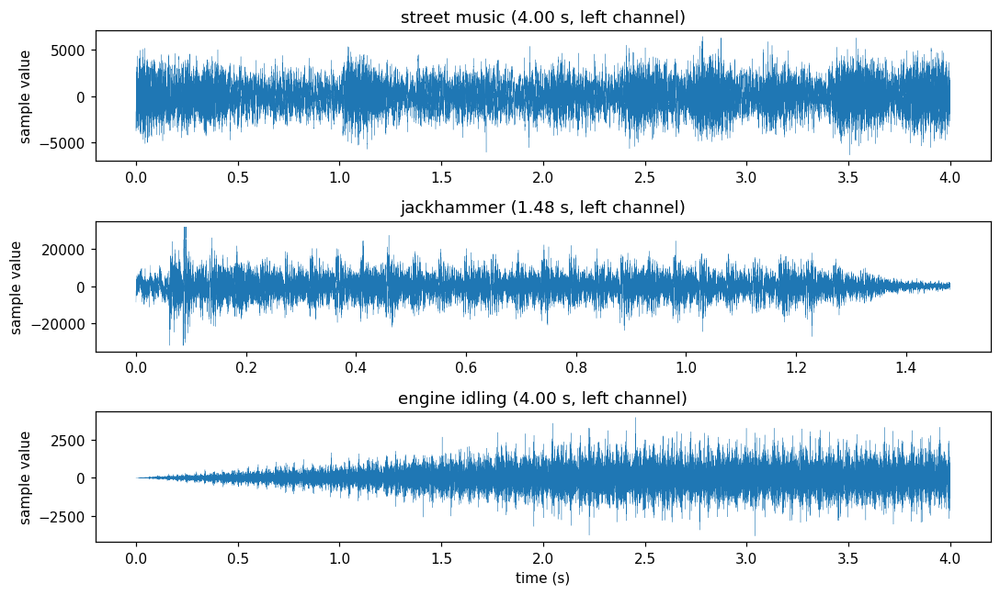

In [45]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6))
for ax, (label, (x, sr)) in zip(axes, audio.items()):
    t = np.arange(len(x)) / sr
    ax.plot(t, x[:, 0], lw=0.2)
    ax.set_title(f'{label} ({len(x) / sr:.2f} s, left channel)')
    ax.set_ylabel('sample value')
axes[-1].set_xlabel('time (s)')
fig.tight_layout()
plt.show()

for label, (x, sr) in audio.items():
    n = min(len(x), 6 * sr)
    display(HTML(f'<b>{label}</b> (original, left channel)'))
    display(Audio(data=x[:n, 0] / 32768.0, rate=sr, normalize=False))

## Byte accounting

An APAC file is a 33-byte header, then per 1024-sample block per coding plane: one control byte (raw / Rice k / constant), LPC coefficients when LPC is chosen (2 bytes each), and the entropy-coded residuals. Stereo is two planes, mid and side. The round trip through the container is asserted bit-exact before each size is reported.

The table also carries the two derived rate metrics: average bits per channel-sample (16 = raw PCM) and bitrate in kbit/s.

In [46]:
def rate_metrics(blob, x, sr):
    # derived rate metrics from the compressed size: avg bits per channel-sample, bitrate
    return {'bits_per_sample': len(blob) * 8 / x.size,
            'bitrate_kbps': len(blob) * 8 * sr / x.shape[0] / 1000}


rows = []
for label, (x, sr) in audio.items():
    apac = TEMP / (label.replace(' ', '_') + '.apac')
    save_apac(apac, compress((x, sr), settings()))
    y, _ = decompress(load_apac(apac))
    assert np.array_equal(y, x), label

    blob = load_apac(apac)
    header, payload = read_apac(blob)
    n_blocks = -(-header.frames // (1 << header.block_size_log2))
    control = header.channels * n_blocks
    params = (header.channels * n_blocks * header.predictor_order * LPC_PARAM_SIZE
              if header.predictor == Predictor.LPC else 0)
    rows.append({'file': label, 'pcm_bytes': pcm_bytes(x), 'apac_bytes': len(blob),
                 'header': HEADER_STRUCT.size, 'control': control, 'lpc_params': params,
                 'coded_audio': len(payload) - control - params,
                 'side_info_%': (HEADER_STRUCT.size + control + params) / len(blob) * 100,
                 **rate_metrics(blob, x, sr)})

# LPC is the only setting that puts coefficient bytes on the wire
xl, srl = audio['street music']
blob = compress((xl, srl), settings(predictor=Predictor.LPC, predictor_order=2))
y, _ = decompress(blob)
assert np.array_equal(y, xl)
header, payload = read_apac(blob)
n_blocks = -(-header.frames // (1 << header.block_size_log2))
control = header.channels * n_blocks
params = control * header.predictor_order * LPC_PARAM_SIZE
rows.append({'file': 'street music (lpc-2)', 'pcm_bytes': pcm_bytes(xl), 'apac_bytes': len(blob),
             'header': HEADER_STRUCT.size, 'control': control, 'lpc_params': params,
             'coded_audio': len(payload) - control - params,
             'side_info_%': (HEADER_STRUCT.size + control + params) / len(blob) * 100,
             **rate_metrics(blob, xl, srl)})
display(pd.DataFrame(rows).set_index('file').round(2))

,pcm_bytes,apac_bytes,header,control,lpc_params,coded_audio,side_info_%,bits_per_sample,bitrate_kbps
file,,,,,,,,,
street music,705600,476353,33,346,0,475974,0.08,10.80,952.71
jackhammer,261072,228502,33,128,0,228341,0.07,14.00,1235.15
engine idling,768000,303435,33,376,0,303026,0.13,6.32,606.87
piano,5292000,1713634,33,2584,0,1711017,0.15,5.18,456.97
street music (lpc-2),705600,544613,33,346,1384,542850,0.32,12.35,1089.23


## Stages

Pipeline: `load_wav` -> mid/side planes -> (optional DCT) -> 1024-sample blocks -> prediction -> quantize -> Rice coding (raw/constant fallback) -> APAC container.

* Prediction: only residuals are coded. The ladder prices every predictor the format offers (LPC at three orders) and the sweep below prices LPC's full order range; the gap to `none` is the stage's savings.
* Mid/side: stores (L+R)/2 and (L-R)/2 instead of L and R. The side plane is near-constant when channels are correlated; the mid plane costs one extra bit. Applied unconditionally.
* Block mode fallback (Rice k / raw / constant): no block is ever stored larger than its raw PCM.

,none,fixed-2 (default),fixed-4,lpc-1,lpc-2,lpc-8,lms-4
file,,,,,,,
street music,82.7,67.5,73.3,68.0,77.2,77.2,64.8
jackhammer,92.1,87.5,91.1,87.1,86.5,87.6,81.5
engine idling,67.3,39.5,42.8,49.9,66.6,70.1,37.1
piano,71.3,32.4,34.2,48.6,70.7,69.4,28.8


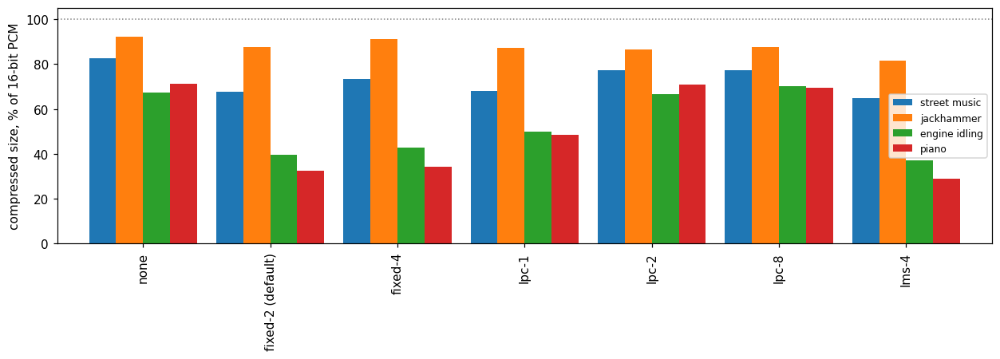

none                 82.7% of PCM   encode  0.05 s   decode  0.10 s
fixed-2 (default)    67.5% of PCM   encode  0.05 s   decode  0.10 s
fixed-4              73.3% of PCM   encode  0.05 s   decode  0.11 s
lpc-1                68.0% of PCM   encode  0.33 s   decode  0.36 s
lpc-2                77.2% of PCM   encode  0.34 s   decode  0.39 s
lpc-8                77.2% of PCM   encode  0.43 s   decode  0.56 s
lms-4                64.8% of PCM   encode  0.86 s   decode  1.77 s

mid/side vs coding the channels separately (payload bytes, header excluded):
street music                       corr +0.63  stereo  476320 B | two monos  454279 B   -> mid/side costs 4.9%
jackhammer                         corr +0.47  stereo  228469 B | two monos  220562 B   -> mid/side costs 3.6%
engine idling                      corr +0.95  stereo  303402 B | two monos  295465 B   -> mid/side costs 2.7%
piano                              corr +0.33  stereo 1713601 B | two monos 1552907 B   -> mid/side costs 10.3%
s

In [47]:
preds = [('none', Predictor.NONE, 0),
         ('fixed-2 (default)', Predictor.FIXED, 2),
         ('fixed-4', Predictor.FIXED, 4),
         ('lpc-1', Predictor.LPC, 1),
         ('lpc-2', Predictor.LPC, 2),
         ('lpc-8', Predictor.LPC, 8),
         ('lms-4', Predictor.LMS, 4)]

rows = []
for label, (x, sr) in audio.items():
    row = {'file': label}
    for name, p, o in preds:
        blob = compress((x, sr), settings(predictor=p, predictor_order=o))
        y, _ = decompress(blob)
        assert np.array_equal(y, x)
        row[name] = len(blob) / pcm_bytes(x) * 100
    rows.append(row)
ladder = pd.DataFrame(rows).set_index('file').round(1)
display(ladder)

ax = ladder.T.plot.bar(figsize=(11.5, 4.2), width=0.85)
ax.axhline(100, color='gray', ls=':', lw=1)
ax.set_ylabel('compressed size, % of 16-bit PCM')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

x, sr = audio['street music']
for name, p, o in preds:
    t0 = time.perf_counter()
    blob = compress((x, sr), settings(predictor=p, predictor_order=o))
    t_enc = time.perf_counter() - t0
    t0 = time.perf_counter()
    decompress(blob)
    t_dec = time.perf_counter() - t0
    print(f'{name:20s} {len(blob) / pcm_bytes(x):5.1%} of PCM   encode {t_enc:5.2f} s   decode {t_dec:5.2f} s')

print()
print('mid/side vs coding the channels separately (payload bytes, header excluded):')
if (CORPUS / '99180-9-0-0.wav').exists():
    meta8, x8 = load_wav(CORPUS / '99180-9-0-0.wav')   # 8 kHz clip with identical channels
    extra = {'street music 8k (identical channels)': (x8, meta8['samplerate'])}
else:
    t8 = np.arange(88200) / 44100
    sig8 = 0.25 * np.sin(2 * np.pi * 220 * t8) + 0.15 * np.sin(2 * np.pi * 277 * t8) + 0.1 * np.sin(2 * np.pi * 440 * t8)
    mono8 = (sig8 * 26000).astype(np.int16)[:, None]
    extra = {'synth chord (identical channels)': (np.concatenate([mono8, mono8], axis=1), 44100)}
for label, (x, sr) in {**audio, **extra}.items():
    corr = float(np.corrcoef(x[:, 0].astype(float), x[:, 1].astype(float))[0, 1])
    stereo = len(compress((x, sr), settings())) - HEADER_STRUCT.size
    monos = sum(len(compress((x[:, c:c + 1], sr), settings())) - HEADER_STRUCT.size for c in range(x.shape[1]))
    print(f'{label:34s} corr {corr:+.2f}  stereo {stereo:7d} B | two monos {monos:7d} B   '
          f'-> mid/side {"saves" if stereo < monos else "costs"} {abs(monos - stereo) / monos:.1%}')

,lpc-1,lpc-2,lpc-4,lpc-8,lpc-16,lpc-32
file,,,,,,
street music,68.0,77.2,76.1,77.2,78.0,79.6
jackhammer,87.1,86.5,87.7,87.6,88.4,89.7
engine idling,49.9,66.6,66.3,70.1,70.4,71.9
piano,48.6,70.7,68.5,69.4,69.8,71.3


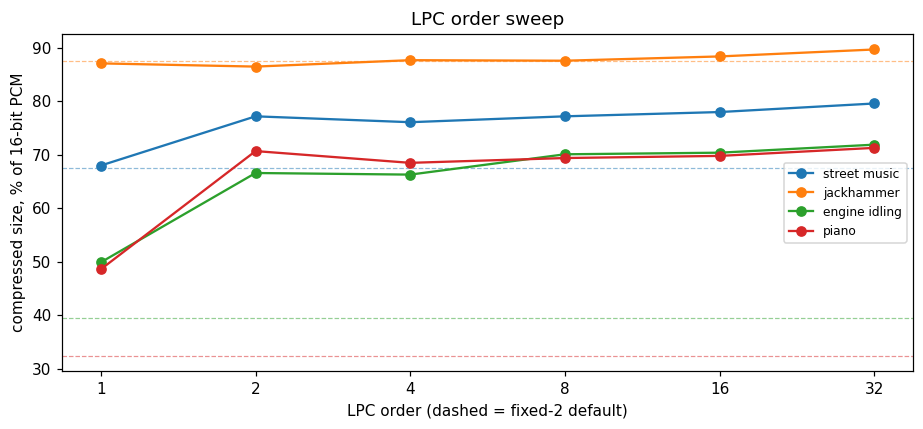

street music   LPC best  lpc-1  68.0%   fixed-2  67.5%   lms-4  64.8%   -> loses to fixed-2, loses to lms-4
jackhammer     LPC best  lpc-2  86.5%   fixed-2  87.5%   lms-4  81.5%   -> beats fixed-2, loses to lms-4
engine idling  LPC best  lpc-1  49.9%   fixed-2  39.5%   lms-4  37.1%   -> loses to fixed-2, loses to lms-4
piano          LPC best  lpc-1  48.6%   fixed-2  32.4%   lms-4  28.8%   -> loses to fixed-2, loses to lms-4
side information: 2 B per coefficient per block plane, so order 32 pays ~3.1% of PCM per plane before any fit gain


In [48]:
orders = [1, 2, 4, 8, 16, 32]
rows = []
for label, (x, sr) in audio.items():
    row = {'file': label}
    for o in orders:
        blob = compress((x, sr), settings(predictor=Predictor.LPC, predictor_order=o))
        y, _ = decompress(blob)
        assert np.array_equal(y, x)
        row[f'lpc-{o}'] = len(blob) / pcm_bytes(x) * 100
    rows.append(row)
lpc_sweep = pd.DataFrame(rows).set_index('file').round(1)
display(lpc_sweep)

fig, ax = plt.subplots(figsize=(8.5, 4))
for i, label in enumerate(lpc_sweep.index):
    ax.plot(orders, lpc_sweep.loc[label], 'o-', color=f'C{i}', label=label)
    ax.axhline(ladder.loc[label, 'fixed-2 (default)'], color=f'C{i}', ls='--', lw=0.8, alpha=0.5)
ax.set_xscale('log', base=2)
ax.set_xticks(orders)
ax.set_xticklabels([str(o) for o in orders])
ax.set_xlabel('LPC order (dashed = fixed-2 default)')
ax.set_ylabel('compressed size, % of 16-bit PCM')
ax.set_title('LPC order sweep')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for label in lpc_sweep.index:
    row = lpc_sweep.loc[label]
    best_o, best = row.idxmin(), row.min()
    f2 = ladder.loc[label, 'fixed-2 (default)']
    lm = ladder.loc[label, 'lms-4']
    print(f"{label:14s} LPC best {best_o:>6s} {best:5.1f}%   fixed-2 {f2:5.1f}%   lms-4 {lm:5.1f}%   "
          f"-> {'beats' if best < f2 else 'loses to'} fixed-2, {'beats' if best < lm else 'loses to'} lms-4")
print('side information: 2 B per coefficient per block plane, so order 32 pays ~3.1% of PCM per plane before any fit gain')


## Edge cases

The assignment asks for shape, data type, empty and tiny inputs next to one unseen file, which has its own section below.

- **Shape**: mono, stereo and an odd 3-channel clip; the plane math (mid/side pairs, leftover pass-through) and the header's channels field must survive all three.
- **Data type**: a FLOAT wav must come back as the exact round + clip int16 cast and round-trip bit-exact; feeding non-int16 (or 1-D, or 0-channel) samples straight to `compress` must fail with a clean `ValueError` instead of silently corrupting anything.
- **Empty**: a 0-frame wav is legal at the container level (`MIN_FRAMES = 0`): it round-trips bit-exact as a 33-byte header-only blob.
- **Tiny**: inputs shorter than one block (1024) and shorter than the predictor order must round-trip bit-exact at the lossless default step and stay bounded by step/2 at step 8.

Test inputs are deterministic patterns or a seeded generator; the codec has no randomness of its own, so this section reproduces exactly.


In [49]:
# edge-case checks: shape, data type, empty and tiny inputs (unseen has its own section)
# everything runs through the real public API, nothing is mocked
t_rng = np.random.default_rng(20260115)

def t_roundtrip(x, sr, **over):
    blob = compress((x, sr), settings(**over))
    y, rate = decompress(blob)
    err = int(np.abs(x.astype(np.int64) - y.astype(np.int64)).max()) if x.size else 0
    return bool(np.array_equal(y, x)), err, rate, len(blob)

def t_rejected(label, data):
    try:
        compress(data, settings())
        print(f'   {label}: ACCEPTED (unexpected!)')
    except ValueError as e:
        print(f'   {label}: ValueError: {e}')

print('shape: mono, stereo and an odd 3-channel clip - bit-exact at the lossless default step')
for name, ch in (('mono', 1), ('stereo', 2), ('odd 3ch', 3)):
    x = (np.cumsum(t_rng.integers(-64, 65, (5000, ch)), axis=0) % 4000 - 2000).astype(np.int16)
    exact, err, rate, size = t_roundtrip(x, 44100)
    assert exact and err == 0 and rate == 44100
    print(f'   {name:9s} {str(x.shape):11s} exact, blob {size} B = {size / pcm_bytes(x):.1%} of PCM')

print('data type: a FLOAT wav takes the subtype route (native read, round + clip to int16), then round-trips bit-exact')
t_pf = TEMP / 't_float.wav'
sf.write(t_pf, np.array([0.0, 0.25, -0.25, 0.75, 1.0, -1.0]), 16000, subtype='FLOAT')
meta, x = load_wav(t_pf)
assert (meta['frames'], meta['channels'], meta['subtype']) == (6, 1, 'FLOAT')
assert np.array_equal(x, np.array([0, 8192, -8192, 24575, 32767, -32767], dtype=np.int16).reshape(-1, 1))
exact, err, rate, _ = t_roundtrip(x, meta['samplerate'])
assert exact and err == 0 and rate == 16000
print(f'   int16 = {x.ravel().tolist()} (0.75 -> 24575, 1.0 clipped to 32767), round trip bit-exact')

print('data type / malformed input: rejected with a clean ValueError before any encoding happens')
t_rejected('float64 samples', (np.zeros((8, 1)), 44100))
t_rejected('1-D samples', (np.zeros(8, dtype=np.int16), 44100))
t_rejected('0 channels', (np.zeros((8, 0), dtype=np.int16), 44100))
t_rejected('sample_rate 0', (np.zeros((8, 1), dtype=np.int16), 0))

print('empty: a 0-frame wav is legal at the container level - bit-exact round trip as a 33-byte header-only blob')
t_ef = TEMP / 't_empty.wav'
save_wav(t_ef, np.zeros((0, 1), dtype=np.int16), 44100)
meta, x = load_wav(t_ef)
assert (meta['frames'], x.shape) == (0, (0, 1))
exact, err, rate, size = t_roundtrip(x, meta['samplerate'])
assert exact and err == 0 and size == 33
print(f'   frames=0 -> blob = {size} B (header only) -> decoded {x.shape} bit-exact')

print('tiny: shorter than one block (1024) and shorter than the predictor order')
for n, ch in ((1, 1), (2, 1), (3, 1), (2, 2), (3, 2)):
    x = (((np.arange(n * ch) * 37) % 251 - 125).astype(np.int16)).reshape(n, ch)
    exact, err, rate, size = t_roundtrip(x, 44100)
    _, err8, _, _ = t_roundtrip(x, 44100, quant_step=8)
    assert exact and err == 0 and rate == 44100 and err8 <= 4
    print(f'   {n}x{ch}: exact at step 1 (blob {size} B), step-8 max|err| = {err8} LSBs (bound step/2 = 4)')
print('all edge-case checks passed')


shape: mono, stereo and an odd 3-channel clip - bit-exact at the lossless default step
   mono      (5000, 1)   exact, blob 5457 B = 54.6% of PCM
   stereo    (5000, 2)   exact, blob 14121 B = 70.6% of PCM
   odd 3ch   (5000, 3)   exact, blob 19047 B = 63.5% of PCM
data type: a FLOAT wav takes the subtype route (native read, round + clip to int16), then round-trips bit-exact
   int16 = [0, 8192, -8192, 24575, 32767, -32767] (0.75 -> 24575, 1.0 clipped to 32767), round trip bit-exact
data type / malformed input: rejected with a clean ValueError before any encoding happens
   float64 samples: ValueError: expected int16 samples, got float64
   1-D samples: ValueError: expected 2D (frames, channels), got 1D
   0 channels: ValueError: expected at least one channel
   sample_rate 0: ValueError: sample_rate must be a positive integer, got 0
empty: a 0-frame wav is legal at the container level - bit-exact round trip as a 33-byte header-only blob
   frames=0 -> blob = 33 B (header only) -> deco

## Rate-quality: quantization step

`quant_step` rounds prediction residuals to multiples of the step. The encoder predicts from its own reconstructed samples, so the error is bounded by step/2 per sample and cannot accumulate.

SNR = 10 log10( sum(x^2) / sum((x - y)^2) ), computed on the int16 samples; bit-exact decode is SNR = inf. FLAC (libsndfile, PCM_16) is the lossless reference.

Rate is reported three ways: % of PCM, average bits per sample (16 = raw PCM), and bitrate in kbit/s - all derived from the same compressed sizes.

size, % of 16-bit PCM:


file,engine idling,jackhammer,piano,street music
step,,,,
1,39.5,87.5,32.4,67.5
2,33.4,81.2,26.5,61.2
4,27.6,75.0,21.0,55.0
8,22.3,68.7,16.5,48.7
16,17.7,62.4,13.5,42.4
32,14.1,56.1,11.7,36.2
64,11.8,49.9,10.8,30.0
128,10.4,43.6,10.1,24.1
256,9.3,37.4,9.4,18.7


SNR, dB (inf = bit exact):


file,engine idling,jackhammer,piano,street music
step,,,,
1,inf,inf,inf,inf
2,62.5,80.1,66.2,70.5
4,57.7,75.4,61.4,65.7
8,52.0,69.7,55.8,60.1
16,46.1,63.8,49.9,54.2
32,40.2,57.8,44.0,48.2
64,34.2,51.8,38.0,42.2
128,28.2,45.8,32.0,36.2
256,22.4,39.8,26.0,30.1


average bits per sample (16 = raw PCM):


file,engine idling,jackhammer,piano,street music
step,,,,
1,6.32,14.00,5.18,10.80
2,5.35,13.00,4.23,9.80
4,4.42,12.00,3.36,8.79
8,3.56,10.99,2.64,7.79
16,2.82,9.99,2.16,6.79
32,2.26,8.98,1.88,5.79
64,1.89,7.98,1.73,4.80
128,1.67,6.98,1.62,3.85
256,1.49,5.98,1.51,3.00


bitrate, kbit/s:


file,engine idling,jackhammer,piano,street music
step,,,,
1,607.0,1235.0,457.0,953.0
2,514.0,1147.0,373.0,864.0
4,424.0,1058.0,296.0,776.0
8,342.0,969.0,233.0,687.0
16,271.0,881.0,191.0,599.0
32,217.0,792.0,166.0,510.0
64,182.0,704.0,153.0,423.0
128,160.0,615.0,143.0,339.0
256,143.0,527.0,133.0,264.0


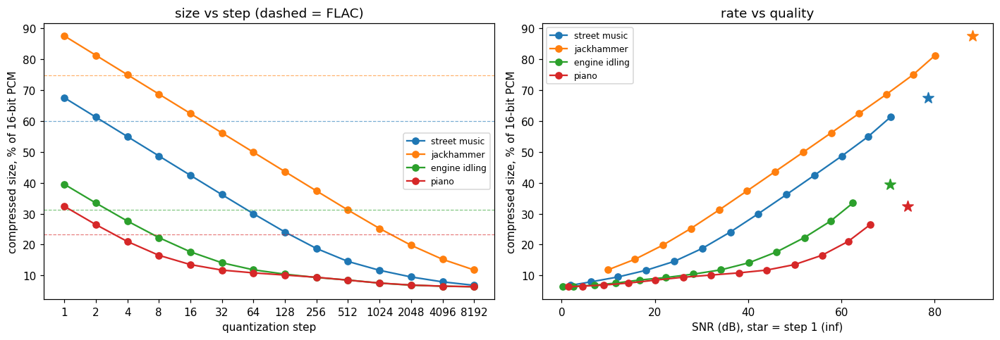

first lossy step below FLAC:
  street music   FLAC  60.0%  ->  step  4 (55.0%, SNR 65.7 dB)
  jackhammer     FLAC  74.8%  ->  step  8 (68.7%, SNR 69.7 dB)
  engine idling  FLAC  31.3%  ->  step  4 (27.6%, SNR 57.7 dB)
  piano          FLAC  23.2%  ->  step  4 (21.0%, SNR 61.4 dB)


In [50]:
def flac_bytes(x, sr, tag):
    p = TEMP / (tag.replace(' ', '_') + '.flac')
    sf.write(p, x, sr, format='FLAC', subtype='PCM_16')
    return p.stat().st_size


steps = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192]
rows = []
flac_pct = {}
for label, (x, sr) in audio.items():
    flac_pct[label] = flac_bytes(x, sr, label) / pcm_bytes(x) * 100
    for st in steps:
        blob = compress((x, sr), settings(quant_step=st))
        y, _ = decompress(blob)
        rows.append({'file': label, 'step': st,
                     'size_%pcm': len(blob) / pcm_bytes(x) * 100,
                     'snr_db': evaluation.snr_db(x, y),
                     'max_err_lsb': int(np.abs(y.astype(np.int32) - x.astype(np.int32)).max()),
                     'bit_exact': bool(np.array_equal(y, x)),
                     'bits_per_sample': len(blob) * 8 / x.size,
                     'bitrate_kbps': len(blob) * 8 * sr / x.shape[0] / 1000})
sweep = pd.DataFrame(rows)
print('size, % of 16-bit PCM:')
display(sweep.pivot(index='step', columns='file', values='size_%pcm').round(1))
print('SNR, dB (inf = bit exact):')
display(sweep.pivot(index='step', columns='file', values='snr_db').round(1))
print('average bits per sample (16 = raw PCM):')
display(sweep.pivot(index='step', columns='file', values='bits_per_sample').round(2))
print('bitrate, kbit/s:')
display(sweep.pivot(index='step', columns='file', values='bitrate_kbps').round(0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {label: f'C{i}' for i, label in enumerate(audio)}
for label, (x, sr) in audio.items():
    sub = sweep[sweep.file == label]
    ax1.plot(sub['step'], sub['size_%pcm'], 'o-', color=colors[label], label=label)
    ax1.axhline(flac_pct[label], color=colors[label], ls='--', lw=0.8, alpha=0.6)
    finite = sub[np.isfinite(sub.snr_db)]
    ax2.plot(finite.snr_db, finite['size_%pcm'], 'o-', color=colors[label], label=label)
    y1 = float(sub.loc[sub.step == 1, 'size_%pcm'].iloc[0])
    ax2.scatter([finite.snr_db.max() + 8], [y1], marker='*', s=110, color=colors[label])
ax1.set_xscale('log', base=2)
ax1.set_xticks(steps)
ax1.set_xticklabels([str(s) for s in steps])
ax1.set_xlabel('quantization step')
ax1.set_ylabel('compressed size, % of 16-bit PCM')
ax1.set_title('size vs step (dashed = FLAC)')
ax1.legend(fontsize=8)
ax2.set_xlabel('SNR (dB), star = step 1 (inf)')
ax2.set_ylabel('compressed size, % of 16-bit PCM')
ax2.set_title('rate vs quality')
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

print('first lossy step below FLAC:')
for label, (x, sr) in audio.items():
    sub = sweep[(sweep.file == label) & (sweep.step > 1)]
    under = sub[sub['size_%pcm'] < flac_pct[label]]
    if len(under):
        first = under.iloc[0]
        print(f"  {label:14s} FLAC {flac_pct[label]:5.1f}%  ->  step {int(first.step):2d} "
              f"({first['size_%pcm']:.1f}%, SNR {first.snr_db:.1f} dB)")
    else:
        print(f"  {label:14s} FLAC {flac_pct[label]:5.1f}%  ->  none up to step {max(steps)}")

In [58]:
# audibility ladder: the same 3 s piano excerpt at increasing quant_step - listen for where artifacts appear
# (rough guide: ~90 dB SNR transparent, ~60 dB noise audible in quiet parts, ~30 dB clearly degraded)
x, sr = audio['piano']
n = min(len(x), 10 * sr)
for st in [1, 8, 32, 64, 128, 512, 2048, 8192]:
    y, _ = decompress(compress((x[:n], sr), settings(quant_step=st)))
    snr = evaluation.snr_db(x[:n], y)
    row = sweep[(sweep.file == 'piano') & (sweep.step == st)].iloc[0]
    display(HTML(f"<b>piano</b> - quant_step {st} "
                 f"({row['size_%pcm']:.1f}% of PCM, SNR {snr:.1f} dB, {row['bitrate_kbps']:.0f} kbit/s)"))
    display(Audio(data=y[:, 0] / 32768.0, rate=sr, normalize=False))


### What we hear

The players above play the same piano excerpt at increasing quantization steps. After listening to these using a over-ear headset [Sony WH1000X](https://www.sony.com/electronics/support/wireless-headphones-bluetooth-headphones/wh-1000xm4/specifications) we charted what artifacts we could perceive at different levels of quantization. 

| quant_step | audible difference from original? | what it sounds like |
|---|---|---|
| 1 | No (lossless reference) | Clear piano playing |
| 8 | No | Clear piano playing |
| 32 | No | Clear piano playing |
| 64 | Yes | Low audible hum in the background |
| 128 | Yes | Louder hum in the background |
| 512 | Yes | Hum now also affects the piano playing noticably |
| 2048 | Yes | Very distorted, but still noticable piano playing, with the hum no longer present |
| 8192 | Yes | Extremely crunched and distorded audio |


## Corpus sweep

`quant_step` 1 to 32 over the corpus, fixed-2 defaults, FLAC (libsndfile, PCM_16) as the lossless reference. The clip set, every size and every SNR in this section are computed in this cell. Median average bits per sample and median bitrate (kbit/s) join the per-step summary.

16 fold1 clips, taking every 1-th by sorted name -> 16 files


   1/16  101415-3-0-2.wav
   2/16  124489-9-0-12.wav
   3/16  17592-5-1-2.wav
   4/16  176787-5-0-0.wav
   5/16  17913-4-0-2.wav
   6/16  21684-9-0-12.wav
   7/16  21684-9-0-7.wav
   8/16  24074-1-0-12.wav
   9/16  31323-3-0-1.wav
  10/16  40722-8-0-2.wav
  11/16  40722-8-0-7.wav
  12/16  7383-3-0-1.wav
  13/16  7383-3-1-0.wav
  14/16  98223-7-9-0.wav
  15/16  99180-9-0-0.wav
  16/16  test-audio-wav-16bit-44khz.wav


,file,pcm_bytes,flac_bytes,apac1,apac2,apac4,apac8,apac16,apac32
0,101415-3-0-2.wav,384000,121029,133439,110941,90645,73439,60025,49470
1,124489-9-0-12.wav,705600,423074,476353,432068,387775,343493,299262,255135
2,17592-5-1-2.wav,705600,349003,383700,339419,295147,251035,207283,165071
3,176787-5-0-0.wav,768000,240693,303435,256835,212063,170910,135556,108350
4,17913-4-0-2.wav,705600,358990,494677,450395,406099,361820,317606,273502
5,21684-9-0-12.wav,705600,415715,453785,409489,365216,320921,276701,232762
6,21684-9-0-7.wav,705600,409287,447102,402817,358533,314286,270056,226088
7,24074-1-0-12.wav,705600,357332,472845,428554,384267,339992,295736,251701
8,31323-3-0-1.wav,705600,320292,412376,368103,323836,279597,235584,192323
9,40722-8-0-2.wav,88200,25445,77216,71584,65952,60320,54688,49056


lossless step 1: 16/16 bit-exact
lossless size vs PCM: APAC 47.5%, FLAC 37.2% (bytes-weighted)
step | %PCM med | x FLAC med | SNR med/min dB | bits/sample med | kbit/s med
   1 |     60.9 |       1.27 |    inf /   inf |            9.74 |       705
   2 |     54.6 |       1.11 |   76.5 /  62.5 |            8.74 |       616
   4 |     48.4 |       0.97 |   70.4 /  57.7 |            7.74 |       528
   8 |     42.1 |       0.81 |   64.8 /  52.0 |            6.73 |       441
  16 |     35.8 |       0.69 |   58.9 /  46.1 |            5.73 |       358
  32 |     29.6 |       0.58 |   52.9 /  40.2 |            4.74 |       283
lossless bitrate medians: APAC 705 kbit/s, FLAC 561 kbit/s
first step with median size below FLAC: 4


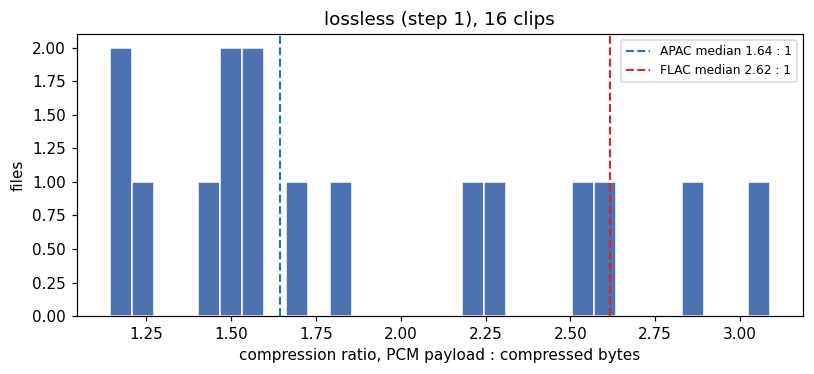

In [52]:
steps = [1, 2, 4, 8, 16, 32]


def sweep_row(name, x, sr):
    rec = {'file': name, 'pcm_bytes': pcm_bytes(x), 'flac_bytes': flac_bytes(x, sr, name),
           'samples': int(x.size), 'frames': int(x.shape[0]), 'samplerate': int(sr)}
    for st in steps:
        blob = compress((x, sr), settings(quant_step=st))
        y, _ = decompress(blob)
        rec[f'apac{st}'] = len(blob)
        rec[f'snr{st}'] = evaluation.snr_db(x, y)
    return rec


rows = []
if HAVE_CORPUS:
    wavs = sorted(CORPUS.glob('*.wav'))
    stride = max(1, len(wavs) // 60)
    files = wavs[::stride][:60]
    print(f'{len(wavs)} fold1 clips, taking every {stride}-th by sorted name -> {len(files)} files')
    for i, path in enumerate(files, 1):
        meta, x = load_wav(path)
        rows.append(sweep_row(path.name, x, meta['samplerate']))
        print(f'  {i:2d}/{len(files)}  {path.name}')
else:
    print('corpus absent, sweeping the demo set instead')
    rows = [sweep_row(label, x, sr) for label, (x, sr) in audio.items()]

cdf = pd.DataFrame(rows)
display(cdf[['file', 'pcm_bytes', 'flac_bytes'] + [f'apac{s}' for s in steps]])

pcm = cdf['pcm_bytes'].to_numpy(float)
flac = cdf['flac_bytes'].to_numpy(float)
sizes = {s: cdf[f'apac{s}'].to_numpy(float) for s in steps}
snrs = {s: cdf[f'snr{s}'].to_numpy(float) for s in steps}
durations = cdf['frames'].to_numpy(float) / cdf['samplerate'].to_numpy(float)
samples = cdf['samples'].to_numpy(float)
bps = {s: sizes[s] * 8 / samples for s in steps}        # avg bits per channel-sample
kbps = {s: sizes[s] * 8 / durations / 1000 for s in steps}  # kbit/s
flac_kbps = flac * 8 / durations / 1000

print(f"lossless step 1: {(snrs[1] == np.inf).sum()}/{len(cdf)} bit-exact")
print(f'lossless size vs PCM: APAC {sizes[1].sum() / pcm.sum():.1%}, FLAC {flac.sum() / pcm.sum():.1%} (bytes-weighted)')
print('step | %PCM med | x FLAC med | SNR med/min dB | bits/sample med | kbit/s med')
for s in steps:
    print(f'{s:4d} | {np.median(sizes[s] / pcm) * 100:8.1f} | {np.median(sizes[s] / flac):10.2f} | '
          f'{np.median(snrs[s]):6.1f} / {np.min(snrs[s]):5.1f} | '
          f'{np.median(bps[s]):15.2f} | {np.median(kbps[s]):9.0f}')
print(f'lossless bitrate medians: APAC {np.median(kbps[1]):.0f} kbit/s, '
      f'FLAC {np.median(flac_kbps):.0f} kbit/s')
under = [s for s in steps[1:] if np.median(sizes[s] / flac) < 1]
print('first step with median size below FLAC:', under[0] if under else f'none up to step {steps[-1]}')

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.hist(pcm / sizes[1], bins=30, color='#4c72b0', edgecolor='white')
ax.axvline(np.median(pcm / sizes[1]), color='C0', ls='--', lw=1.4,
           label=f'APAC median {np.median(pcm / sizes[1]):.2f} : 1')
ax.axvline(np.median(pcm / flac), color='C3', ls='--', lw=1.4,
           label=f'FLAC median {np.median(pcm / flac):.2f} : 1')
ax.set_xlabel('compression ratio, PCM payload : compressed bytes')
ax.set_ylabel('files')
ax.set_title(f'lossless (step 1), {len(cdf)} clips')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## DCT pre-shaping

The header carries one `dct_param` (uint32) and a single encoder-side mode beyond OFF: QUANTIZE, the JPEG-style quality knob that was the intent from the start (an earlier hard CUTOFF wall and a per-mille ATTENUATE scale were retired - a frequency wall is only defensible at 15 kHz and up, and a global scale is no rate knob at all). Each window goes through a forward DCT, every bin snaps to a multiple of a per-bin step from a frequency-weighted base table (1 at DC, window_size/32 per bin index, about 32700 at the top of the default 1024 window) scaled libjpeg-style by `dct_param` as quality 1-100, then the inverse DCT rounds back to int32. Lower quality coarsens the high end first, no frequency is ever walled off, and 100 keeps every step at 1 - only transform rounding remains, bit-exact on this clip. The table is derived from `dct_param` and the window size, never stored, so the wire format keeps its single uint32 and the decoder stays a no-op. SNR under-reads the shaping: the error concentrates in the high frequencies, where hearing is least sensitive. The trial prices the quality ladder against `quant_step` on the tonal and the broadband clip, reporting size as % of PCM plus the derived average bits per sample and bitrate. The players below make both knobs audible on the tonal clip: the original, two DCT qualities, and four `quant_step` variants from 4 (the CLI default lossy step) to 256 - unlike the DCT, whose error concentrates where hearing is least sensitive, the step ladder's error is broadband, so the coarse steps are the audibly rough ones.

,size_%pcm,snr_db,max_err_lsb,bit_exact,bits_per_sample,bitrate_kbps
variant,,,,,,
"original (dct off, lossless)",32.4,inf,0,True,5.2,457.0
quantize q=100,32.4,inf,0,True,5.2,457.0
quantize q=90,30.1,51.1,98,False,4.8,425.3
quantize q=50,30.2,43.9,279,False,4.8,426.2
quantize q=10,30.4,35.8,542,False,4.9,428.7
quant_step 2 (rate knob),26.5,66.2,1,False,4.2,373.4
quant_step 4 (rate knob),21.0,61.4,2,False,3.4,296.3
quant_step 8 (rate knob),16.5,55.8,4,False,2.6,233.2
quant_step 16 (rate knob),13.5,49.9,8,False,2.2,190.8


,size_%pcm,snr_db,bits_per_sample,bitrate_kbps
jackhammer,,,,
quantize q=50,87.5,38.1,14.0,1235.5
quantize q=10,87.6,26.2,14.0,1236.1
quant_step 4 (rate knob),75.0,75.4,12.0,1058.0
quant_step 8 (rate knob),68.7,69.7,11.0,969.4
quant_step 16 (rate knob),62.4,63.8,10.0,880.9


quality 100 is transparent and the ladder coarsens the high end first, but even q=10 (30.4% at 35.8 dB) loses to quant_step 8 (16.5% at 55.8 dB); quant_step stays the rate-quality knob


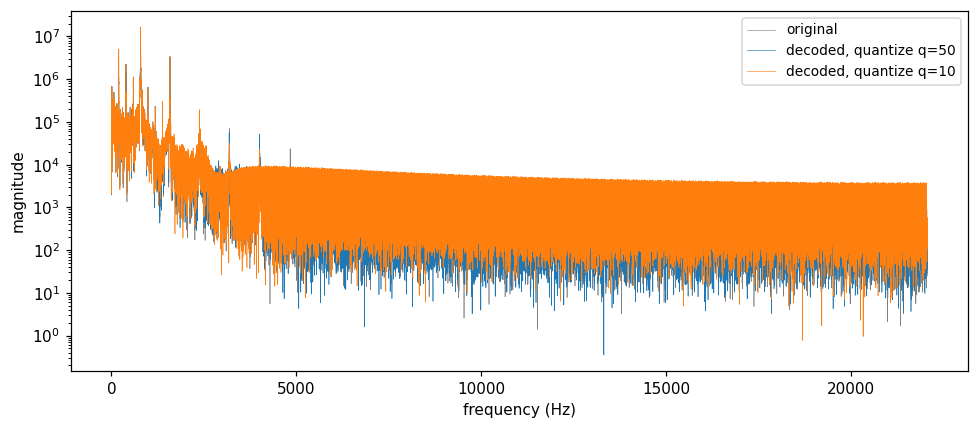

In [56]:
x, sr = audio['piano']
variants = [('original (dct off, lossless)', settings()),
            ('quantize q=100', settings(dct_mode=DCTMode.QUANTIZE, dct_param=100, dct_window_size=1024)),
            ('quantize q=90', settings(dct_mode=DCTMode.QUANTIZE, dct_param=90, dct_window_size=1024)),
            ('quantize q=50', settings(dct_mode=DCTMode.QUANTIZE, dct_param=50, dct_window_size=1024)),
            ('quantize q=10', settings(dct_mode=DCTMode.QUANTIZE, dct_param=10, dct_window_size=1024)),
            ('quant_step 2 (rate knob)', settings(quant_step=2)),
            ('quant_step 4 (rate knob)', settings(quant_step=4)),
            ('quant_step 8 (rate knob)', settings(quant_step=8)),
            ('quant_step 16 (rate knob)', settings(quant_step=16)),
            ('quant_step 32 (rate knob)', settings(quant_step=32)),
            ('quant_step 64 (rate knob)', settings(quant_step=64)),
            ('quant_step 128 (rate knob)', settings(quant_step=128)),
            ('quant_step 256 (rate knob)', settings(quant_step=256)),
            ('quant_step 512 (rate knob)', settings(quant_step=512)),
            ('quant_step 1024 (rate knob)', settings(quant_step=1024))]

rows, decoded = [], {}
for name, over in variants:
    blob = compress((x, sr), over)
    y, _ = decompress(blob)
    decoded[name] = y
    rows.append({'variant': name, 'size_%pcm': len(blob) / pcm_bytes(x) * 100,
                 'snr_db': evaluation.snr_db(x, y),
                 'max_err_lsb': int(np.abs(y.astype(np.int32) - x.astype(np.int32)).max()),
                 'bit_exact': bool(np.array_equal(y, x)),
                 'bits_per_sample': len(blob) * 8 / x.size,
                 'bitrate_kbps': len(blob) * 8 * sr / x.shape[0] / 1000})
display(pd.DataFrame(rows).set_index('variant').round(1))

jx, jsr = audio['jackhammer']
jrows = []
for name, over in [('quantize q=50', settings(dct_mode=DCTMode.QUANTIZE, dct_param=50, dct_window_size=1024)),
                   ('quantize q=10', settings(dct_mode=DCTMode.QUANTIZE, dct_param=10, dct_window_size=1024)),
                   ('quant_step 4 (rate knob)', settings(quant_step=4)),
                   ('quant_step 8 (rate knob)', settings(quant_step=8)),
                   ('quant_step 16 (rate knob)', settings(quant_step=16)),]:
    blob = compress((jx, jsr), over)
    y, _ = decompress(blob)
    jrows.append({'jackhammer': name, 'size_%pcm': len(blob) / pcm_bytes(jx) * 100,
                  'snr_db': evaluation.snr_db(jx, y),
                  'bits_per_sample': len(blob) * 8 / jx.size,
                  'bitrate_kbps': len(blob) * 8 * jsr / jx.shape[0] / 1000})
display(pd.DataFrame(jrows).set_index('jackhammer').round(1))

q10 = next(r for r in rows if r['variant'] == 'quantize q=10')
s8 = next(r for r in rows if r['variant'] == 'quant_step 8 (rate knob)')
print(f"quality 100 is transparent and the ladder coarsens the high end first, but even q=10 "
      f"({q10['size_%pcm']:.1f}% at {q10['snr_db']:.1f} dB) loses to quant_step 8 "
      f"({s8['size_%pcm']:.1f}% at {s8['snr_db']:.1f} dB); quant_step stays the rate-quality knob")

players = ['original (dct off, lossless)', 'quantize q=50', 'quantize q=10',
           'quant_step 4 (rate knob)', 'quant_step 16 (rate knob)',
           'quant_step 64 (rate knob)', 'quant_step 256 (rate knob)']
n = min(len(x), 3 * sr)
for name in players:
    display(HTML(f'<b>piano</b> - {name}'))
    display(Audio(data=decoded[name][:n, 0] / 32768.0, rate=sr, normalize=False))

freqs = np.fft.rfftfreq(n, 1 / sr)
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(freqs, np.abs(np.fft.rfft(x[:n, 0].astype(np.float64))), lw=0.4, color='gray', label='original')
ax.semilogy(freqs, np.abs(np.fft.rfft(decoded['quantize q=50'][:n, 0].astype(np.float64))), lw=0.4,
            color='C0', label='decoded, quantize q=50')
ax.semilogy(freqs, np.abs(np.fft.rfft(decoded['quantize q=10'][:n, 0].astype(np.float64))), lw=0.4,
            color='C1', label='decoded, quantize q=10')
ax.set_xlabel('frequency (Hz)')
ax.set_ylabel('magnitude')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## Float WAV loader bug

`sf.read(dtype='int16')` returns all zeros for FLOAT wavs on soundfile 0.13.1 / libsndfile 1.2.2. The first `load_wav` used that call for every input, so float sources loaded as silence. The fix routes by subtype: int16 read for PCM_U8/PCM_16, u-law, a-law, ADPCM; float64 read plus round-and-clip for wider subtypes, error bounded at 0.5 LSB.

float sine, old path:   0/44100 samples non-zero
float sine, fixed path:  44080/44100 samples non-zero
(soundfile 0.13.1 / libsndfile 1.2.2; failure observed on libsndfile 1.2.2)



engine idling (FLOAT): old path 0/384000 non-zero, fixed path 382913/384000 non-zero
cast cost of the fixed path: max |err| 0.500 LSB (bound 0.5 LSB)


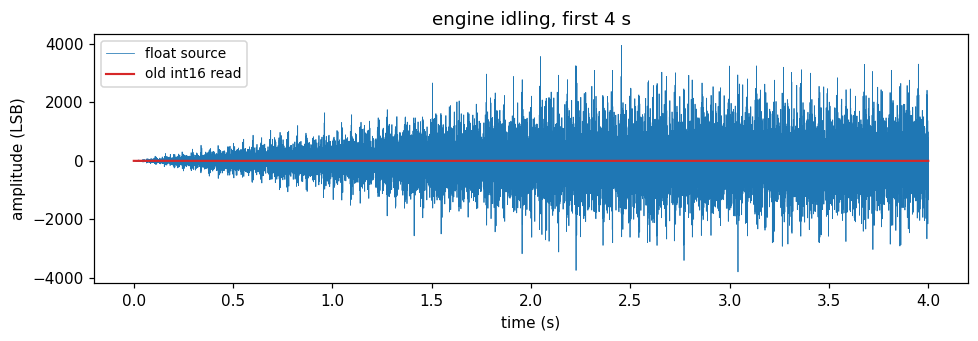

In [54]:
sr = 44100
t = np.arange(sr) / sr
sine = (0.4 * np.sin(2 * np.pi * 440 * t))[:, None]

pf = TEMP / 'sine_float.wav'
sf.write(pf, sine, sr, subtype='FLOAT')

old_read, _ = sf.read(pf, dtype='int16', always_2d=True)   # what load_wav used to do
_, fixed = load_wav(pf)

print(f'float sine, old path:   {np.count_nonzero(old_read)}/{old_read.size} samples non-zero')
print(f'float sine, fixed path:  {np.count_nonzero(fixed)}/{fixed.size} samples non-zero')
print(f'(soundfile {sf.__version__} / libsndfile {sf.__libsndfile_version__}; failure observed on libsndfile 1.2.2)')

display(HTML('old loader (sf.read as int16):'))
display(Audio(data=old_read[:, 0] / 32768.0, rate=sr, normalize=False))
display(HTML('fixed loader (load_wav):'))
display(Audio(data=fixed[:, 0] / 32768.0, rate=sr, normalize=False))

if HAVE_CORPUS:
    src = CORPUS / DEMO_FILES['engine idling']
    esr = audio['engine idling'][1]
    old_full, _ = sf.read(src, dtype='int16', always_2d=True)
    _, loader = load_wav(src)
    truth, _ = sf.read(src, dtype='float64', always_2d=True)
    cast_err = loader / 32767.0 - truth
    print()
    print(f'engine idling (FLOAT): old path {np.count_nonzero(old_full)}/{old_full.size} non-zero, '
          f'fixed path {np.count_nonzero(loader)}/{loader.size} non-zero')
    print(f'cast cost of the fixed path: max |err| {np.abs(cast_err).max() * 32768:.3f} LSB (bound 0.5 LSB)')
    n = min(len(truth), int(4 * esr))
    tt = np.arange(n) / esr
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(tt, truth[:n, 0] * 32768, lw=0.5, label='float source')
    ax.plot(tt, np.zeros(n), lw=1.4, color='C3', label='old int16 read')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('amplitude (LSB)')
    ax.set_title('engine idling, first 4 s')
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()
    display(HTML('engine idling, fixed loader (first 4 s, left channel):'))
    display(Audio(data=loader[:n, 0] / 32768.0, rate=esr, normalize=False))
else:
    print('corpus absent: the float sine above is the replay')

## Unseen file: held-out check

This section introduces a new file from outside the corpus the codec was tested with as a final test of generalization.

- **Load** through the same loader the CLI uses (`load_wav`).
- **Lossless check** `quant_step 1` must round-trip bit-exact.
- **Predictor ladder** all seven predictors re-ranked on this file.
- **Rate-quality sweep** over the quantization steps.
- **Listen** original, step-1 decode (bit-identical) and a step-16 decode for A/B; the plot shows what step 16 actually changed.


test-audio-wav-16bit-44khz.wav: 30.00 s, 44100 Hz, 2 ch, subtype PCM_16, 1323000 frames
lossless (quant_step 1): bit-exact, 32.4% of PCM, 5.18 bits/sample, 457 kbit/s
FLAC-16:                23.2% of PCM  ->  APAC is 1.40x the FLAC size
predictor ladder, % of PCM:
  none                  71.3
  fixed-2 (default)     32.4
  fixed-4               34.2
  lpc-1                 48.6
  lpc-2                 70.7
  lpc-8                 69.4
  lms-4                 28.8
  best on this file: lms-4 at 28.8% of PCM


,size_%pcm,snr_db,bits_per_sample,bit_exact
step,,,,
1,32.38,inf,5.18,True
2,26.46,66.18,4.23,False
4,20.99,61.42,3.36,False
8,16.53,55.82,2.64,False
16,13.52,49.94,2.16,False
32,11.74,43.98,1.88,False


first lossy step below FLAC: step 4 (21.0% of PCM, SNR 61.4 dB)


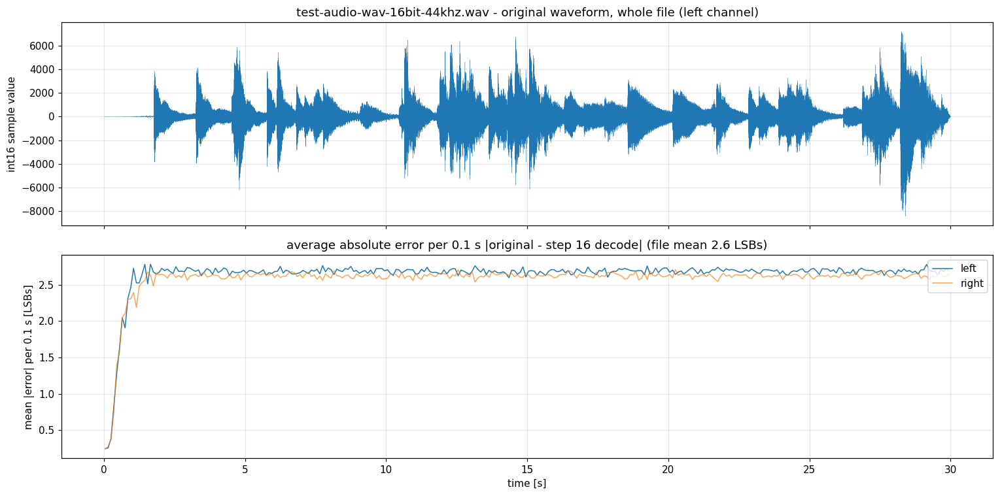

In [55]:
UNSEEN_DIR = Path('unseen')
if not UNSEEN_DIR.is_dir():
    raise FileNotFoundError(f'unseen folder not found: {UNSEEN_DIR.resolve()}')
u_wavs = sorted(UNSEEN_DIR.glob('*.wav'))
if not u_wavs:
    raise FileNotFoundError(
        f'no wav in {UNSEEN_DIR.resolve()} - drop the unseen clip there and re-run this cell')
UNSEEN = u_wavs[0]
if len(u_wavs) > 1:
    print(f'{len(u_wavs)} wavs in unseen/, using the first by name: {UNSEEN.name}')

meta_u, u_x = load_wav(UNSEEN)   # same loader the CLI uses; PCM_16 is read directly as int16 (no quantization)
u_sr = meta_u['samplerate']
assert meta_u['subtype'] == 'PCM_16', (
    f'this section expects a 16-bit PCM wav, but {UNSEEN.name} is {meta_u["subtype"]!r}')
print(f"{UNSEEN.name}: {meta_u['duration']:.2f} s, {u_sr} Hz, {meta_u['channels']} ch, "
      f"subtype {meta_u['subtype']}, {len(u_x)} frames")

# lossless round-trip at step 1 must be bit-exact; FLAC-16 as the size reference
u_blob = compress((u_x, u_sr), settings(quant_step=1))
u_rec, _ = decompress(u_blob)
assert np.array_equal(u_rec, u_x), 'step-1 round-trip is not bit-exact'

u_flac_p = TEMP / 'unseen.flac'
sf.write(u_flac_p, u_x, u_sr, format='FLAC', subtype='PCM_16')
u_flac = u_flac_p.stat().st_size

print(f'lossless (quant_step 1): bit-exact, {len(u_blob) / pcm_bytes(u_x):.1%} of PCM, '
      f'{len(u_blob) * 8 / u_x.size:.2f} bits/sample, {len(u_blob) * 8 / meta_u["duration"] / 1000:.0f} kbit/s')
print(f'FLAC-16:                {u_flac / pcm_bytes(u_x):.1%} of PCM  '
      f'->  APAC is {len(u_blob) / u_flac:.2f}x the FLAC size')

# predictor ladder re-ranked on this file (the fixed-2 default need not win on unseen material)
u_preds = [('none', Predictor.NONE, 0), ('fixed-2 (default)', Predictor.FIXED, 2),
           ('fixed-4', Predictor.FIXED, 4), ('lpc-1', Predictor.LPC, 1),
           ('lpc-2', Predictor.LPC, 2), ('lpc-8', Predictor.LPC, 8),
           ('lms-4', Predictor.LMS, 4)]
u_ladder = {name: len(compress((u_x, u_sr), settings(predictor=p, predictor_order=o)))
            / pcm_bytes(u_x) * 100 for name, p, o in u_preds}
print('predictor ladder, % of PCM:')
for name, pct in u_ladder.items():
    print(f'  {name:20s} {pct:5.1f}')
u_best = min(u_ladder, key=u_ladder.get)
print(f'  best on this file: {u_best} at {u_ladder[u_best]:.1f}% of PCM')

# rate-quality sweep (inf SNR = bit exact), then the first lossy step that undercuts FLAC
u_rows = []
for st in (1, 2, 4, 8, 16, 32):
    b = compress((u_x, u_sr), settings(quant_step=st))
    y, _ = decompress(b)
    u_rows.append({'step': st, 'size_%pcm': len(b) / pcm_bytes(u_x) * 100,
                   'snr_db': evaluation.snr_db(u_x, y),
                   'bits_per_sample': len(b) * 8 / u_x.size,
                   'bit_exact': bool(np.array_equal(y, u_x))})
u_sweep = pd.DataFrame(u_rows).set_index('step')
display(u_sweep.round(2))

u_under = u_sweep[(u_sweep.index > 1) & (u_sweep['size_%pcm'] < u_flac / pcm_bytes(u_x) * 100)]
if len(u_under):
    f0 = u_under.iloc[0]
    print(f'first lossy step below FLAC: step {int(f0.name)} '
          f'({f0["size_%pcm"]:.1f}% of PCM, SNR {f0.snr_db:.1f} dB)')
else:
    print(f'no lossy step up to 32 undercuts FLAC ({u_flac / pcm_bytes(u_x):.1%} of PCM) on this file')

# listen to the actual audio: the whole clip, stereo as stored.
# u_play = None embeds the entire file; set it to a number of seconds (e.g. 10)
# to embed only a prefix - full-length stereo players add ~20 MB to the .ipynb
u_play = None
u_lossy, _ = decompress(compress((u_x, u_sr), settings(quant_step=16)))
u_stop = len(u_x) if u_play is None else min(len(u_x), int(u_play * u_sr))
for cap, arr in (('original', u_x), ('step 1 decode (bit-identical)', u_rec),
                 ('step 16 decode (lossy - A/B against the original)', u_lossy)):
    display(HTML(f'<b>{UNSEEN.name}</b> - {cap} ({meta_u["channels"]} ch, {u_stop / u_sr:.0f} s)'))
    display(Audio(data=arr[:u_stop].T / 32768.0, rate=u_sr, normalize=False))


# and see the damage without overlaying the two signals: the whole file first
# as the original waveform for context, then how far the lossy decode drifts
# from the original over time, as the average absolute error per 0.1 s bin
u_bin = u_sr // 10                                   # 0.1 s per bin
u_nb = len(u_x) // u_bin                             # whole 0.1 s bins in the file
u_err = np.abs(u_x.astype(np.int32) - u_lossy.astype(np.int32))  # int32 first: int16 subtraction would wrap

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# top: the actual waveform, whole file (left channel) - context, no overlay
ax1.plot(np.arange(len(u_x)) / u_sr, u_x[:, 0], lw=0.2)
ax1.set_title(f'{UNSEEN.name} - original waveform, whole file (left channel)')
ax1.set_ylabel('int16 sample value')
ax1.grid(alpha=0.3)

# bottom: average absolute error |original - step 16 decode| per 0.1 s bin
u_avg = u_err[:u_nb * u_bin].reshape(u_nb, u_bin, -1).mean(axis=1)
u_t = (np.arange(u_nb) + 0.5) * u_bin / u_sr         # bin centres, in seconds
ax2.plot(u_t, u_avg[:, 0], lw=1.0, label='left')
ax2.plot(u_t, u_avg[:, 1], lw=1.0, alpha=0.7, label='right')
ax2.set_title('average absolute error per 0.1 s |original - step 16 decode| '
              f'(file mean {u_err.mean():.1f} LSBs)')
ax2.set_xlabel('time [s]')
ax2.set_ylabel('mean |error| per 0.1 s [LSBs]')
ax2.legend(loc='upper right')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


